# Pricing and hedging an option book

*Black–Scholes finite differences, American exercise, and a historical S&P 500 hedging experiment*

## What I wanted to test

The starting point for this project was a practical question: **how much risk is actually removed when an option desk adds progressively more sophisticated hedges?** Delta hedging is the usual first answer, but it only addresses first-order changes in the underlying. An option book also reacts to curvature, time passing, and changes in implied volatility.

I first build a pricing engine so the hedges can be computed consistently. The Black–Scholes equation is transformed into the heat equation and solved on a grid. European contracts use a tridiagonal solver; American puts require an early-exercise constraint, handled by projected successive over-relaxation (PSOR). I check prices and Greeks against analytic Black–Scholes formulas, a binomial tree, and Monte Carlo estimates before using them for hedging.

The second half of the notebook applies the engine to a simple three-option book over **S&P 500 and VIX observations from 1999–2018**. I compare no hedge, a fixed delta hedge, daily delta rebalancing, and option hedges that neutralize gamma and vega at initiation. I then look at changes in the outcome across volatility regimes, the effect of transaction costs, and the performance of three one-day VaR methods.

## How the notebook is organized

1. Derive the PDE and its heat-equation representation.
2. Implement Crank–Nicolson, Rannacher start-up, and American exercise with PSOR.
3. Validate the numerical methods, including Greeks and Monte Carlo benchmarks.
4. Check a discrete-delta hedge in simulated Black–Scholes paths.
5. Define the option book and evaluate the different hedges on historical index and volatility data.
6. Compare tail risk, transaction costs, and VaR back-tests.

## Scope of the project

The empirical exercise uses **model-based option prices**, not historical option quotes. Each strike and maturity is marked at the day's VIX divided by 100, with a flat volatility surface and a constant 2% risk-free rate; dividends are ignored. The book includes an American-style put even though standard SPX index options are European. These choices make the different hedge rules comparable, but mean that the P&L figures are illustrative rather than an executable trading back-test. The monthly windows do not overlap, although observations can still be dependent across market regimes.


In [ ]:
import math
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln
from IPython.display import display, Markdown
warnings.filterwarnings("ignore", category=RuntimeWarning)

try:
    from numba import njit
    HAVE_NUMBA = True
except Exception:
    HAVE_NUMBA = False

    def njit(*a, **k):
        if len(a) == 1 and callable(a[0]) and not k:
            return a[0]
        return lambda f: f
print("numba available:", HAVE_NUMBA)

QUICK = os.environ.get("QUICK", "0") == "1"   # Set QUICK=1 in the environment for a shorter development run (not directly comparable with the full-sample results)

# pallete consistency
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK2 = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6, "figure.dpi": 110, "font.size": 10,
})

numba available: True


## 2. From the stock model to the pricing equation

### 2.1 The model
I take the underlying to follow **geometric Brownian motion** with constant volatility $\sigma$, constant interest rate $r$ and no dividends:

$$dS_t=\mu S_t\,dt+\sigma S_t\,dW_t .$$

For a derivative with value $V(S,t)$, **Itô's lemma** gives

$$dV=\Big(V_t+\mu S\,V_S+\tfrac12\sigma^2S^2V_{SS}\Big)dt+\sigma S\,V_S\,dW_t .$$

### 2.2 The Black–Scholes PDE: derivation by delta hedging
Form the portfolio $\Pi=V-\Delta S$ (long the option, short $\Delta$ shares) with $\Delta$ held fixed over $dt$:

$$d\Pi=dV-\Delta\,dS=\Big(V_t+\mu S\,V_S+\tfrac12\sigma^2S^2V_{SS}-\Delta\mu S\Big)dt+\big(\sigma S\,V_S-\Delta\sigma S\big)dW_t .$$

Choosing $\Delta=V_S$ removes the random term **and** the drift $\mu$, so the portfolio is instantaneously riskless: $d\Pi=\big(V_t+\tfrac12\sigma^2S^2V_{SS}\big)dt$.
No-arbitrage forces a riskless portfolio to earn the risk-free rate, $d\Pi=r\Pi\,dt=r(V-SV_S)\,dt$, hence the **Black–Scholes PDE**

$$\boxed{\;\frac{\partial V}{\partial t}+\tfrac12\sigma^2S^2\frac{\partial^2V}{\partial S^2}+rS\frac{\partial V}{\partial S}-rV=0\;}$$

There are three useful consequences:
* The real-world drift $\mu$ has **disappeared**: the price depends only on $\sigma$ and $r$ (risk-neutral valuation). Equivalently, by Feynman–Kac, $V=e^{-r(T-t)}\,\mathbb E^{\mathbb Q}[\text{payoff}]$ with $dS=rS\,dt+\sigma S\,dW^{\mathbb Q}$.
* It is a **backward parabolic** PDE: the condition is given at expiry $T$ and we solve towards today. It is a convection–diffusion–reaction equation with variable coefficients (diffusion $\tfrac12\sigma^2S^2$, convection $rS$, reaction $-r$).
* $\Delta=V_S$ is the **hedge ratio** that the hedging study in §8 uses, and $\Gamma=V_{SS}$ measures how fast that hedge goes stale.

### 2.3 Terminal and boundary conditions
| Contract | Terminal condition $V(S,T)$ | At $S\to0$ | At $S\to\infty$ |
|---|---|---|---|
| European call | $(S-K)^+$ | $0$ | $S-Ke^{-r(T-t)}$ |
| European put | $(K-S)^+$ | $Ke^{-r(T-t)}$ | $0$ |
| American put | $(K-S)^+$ **and** $V\ge(K-S)^+$ at all times | $K$ (exercise immediately) | $0$ |

### 2.4 Mapping to the heat equation, step by step
The terms involving $S$ and $S^2$ would lead to a nonuniform numerical problem in spot space. Working in log-price makes the discretization much simpler.

**Step 1: log-price and time-to-maturity.** Let $S=Ke^{x}$, $t=T-\dfrac{2\tau}{\sigma^2}$ and $V(S,t)=K\,v(x,\tau)$. By the chain rule
$$S\,V_S=K\,v_x,\qquad S^2V_{SS}=K\,(v_{xx}-v_x),\qquad V_t=-\tfrac12\sigma^2K\,v_\tau .$$
Substituting into the PDE and dividing by $\tfrac12\sigma^2K$, with the single dimensionless parameter $k=\dfrac{2r}{\sigma^2}$:
$$\boxed{\;v_\tau=v_{xx}+(k-1)\,v_x-k\,v\;}$$
The coefficients are now constant, and time runs *forward* from expiry ($\tau=0$) to today ($\tau=\tfrac12\sigma^2T$), so the terminal-value problem is an initial-value problem.

**Step 2: remove the convection and reaction terms.** Write $v=e^{\alpha x+\beta\tau}\,y(x,\tau)$. Then $v_\tau=e^{\alpha x+\beta\tau}(\beta y+y_\tau)$, $v_x=e^{\alpha x+\beta\tau}(\alpha y+y_x)$, $v_{xx}=e^{\alpha x+\beta\tau}(\alpha^2y+2\alpha y_x+y_{xx})$, and the equation becomes
$$y_\tau+\beta y=y_{xx}+\big(2\alpha+k-1\big)y_x+\big(\alpha^2+(k-1)\alpha-k\big)y .$$
Choose $\alpha$ to kill the $y_x$ term and $\beta$ to kill the $y$ term:
$$2\alpha+k-1=0\;\Rightarrow\;\alpha=-\tfrac12(k-1),\qquad \beta=\alpha^2+(k-1)\alpha-k=-\tfrac14(k+1)^2 .$$

**Result.**
$$\boxed{\;V(S,t)=K\,e^{-\frac12(k-1)x-\frac14(k+1)^2\tau}\;y(x,\tau),\qquad \frac{\partial y}{\partial\tau}=\frac{\partial^2y}{\partial x^2}\;}$$
with initial data $y(x,0)=e^{\frac12(k-1)x}\,v(x,0)$:
* call: $y(x,0)=\max\!\big(e^{\frac12(k+1)x}-e^{\frac12(k-1)x},\,0\big)$,
* put: $y(x,0)=\max\!\big(e^{\frac12(k-1)x}-e^{\frac12(k+1)x},\,0\big)$.

Boundary values follow from §2.3 by the same substitution (e.g. a European put at $x=-L$: $y=e^{-\frac12(k-1)L+\frac14(k+1)^2\tau}\,(e^{-k\tau}-e^{-L})$, since $r(T-t)=k\tau$).

**Why use this transformation?** (i) a *constant-coefficient* operator means a uniform grid and a constant tridiagonal matrix (cheap, and the same matrix at every step); (ii) the whole problem depends on the *single* dimensionless number $k$;
(iii) the heat equation is the best-understood PDE there is, with an exact solution, a maximum principle and a textbook stability theory that carries over directly to the discrete scheme.

### 2.5 The exact solution: Gaussian smoothing of the payoff
The heat equation on the whole line is solved by convolution with the **heat kernel**:
$$y(x,\tau)=\frac{1}{\sqrt{4\pi\tau}}\int_{-\infty}^{\infty}y(\xi,0)\,e^{-\frac{(x-\xi)^2}{4\tau}}\,d\xi .$$
Inserting the call initial condition and completing the square gives
$$y(x,\tau)=e^{\frac12(k+1)x+\frac14(k+1)^2\tau}\,N(d_1)-e^{\frac12(k-1)x+\frac14(k-1)^2\tau}\,N(d_2),\quad d_{1,2}=\frac{x}{\sqrt{2\tau}}+\tfrac12(k\pm1)\sqrt{2\tau},$$
which, transformed back through the boxed relation above, is exactly the **Black–Scholes formula**. One way to interpret the result is that the payoff is *diffused* for a time $\tau=\tfrac12\sigma^2(T-t)$: volatility plays the role of the diffusion constant and the kink of the payoff is smoothed out into a smooth value curve. §3.8 verifies all of this numerically.

### 2.6 American options: an obstacle problem (free boundary)
For an American put the holder can exercise at any time, so the no-arbitrage constraint $V\ge(K-S)^+$ holds everywhere. In transformed variables this becomes $y(x,\tau)\ge g(x,\tau)$ with
$$g(x,\tau)=e^{\frac12(k-1)x+\frac14(k+1)^2\tau}\max(1-e^{x},0),$$
and the PDE only has to hold where the option is **not** exercised. The full statement is a **linear complementarity problem**
$$\big(y_\tau-y_{xx}\big)\ge0,\qquad y\ge g,\qquad \big(y_\tau-y_{xx}\big)\,(y-g)=0 .$$
Either we are in the continuation region ($y>g$ and the heat equation holds) or in the exercise region ($y=g$). The interface between them, the **optimal exercise boundary** $S^*(t)$, is not known in advance but is part of the solution; this is the structure of a **Stefan-type free-boundary problem** (like the melting front of ice).
It has no closed form, which is why a numerical solver is required.

## 3. Discretizing the pricing problem

### 3.1 Grid and the θ-scheme
Truncate $x\in[-L,L]$ with a **uniform grid** $x_i=-L+ih$, $h=2L/N_x$, and $N_t$ steps of size $\Delta\tau=\tfrac12\sigma^2T/N_t$. Let $y_i^n\approx y(x_i,n\Delta\tau)$ and $\alpha=\Delta\tau/h^2$.
Replace $y_{xx}$ by the central difference $Ly_i=y_{i+1}-2y_i+y_{i-1}$ (divided by $h^2$) and average the right-hand side between the old and the new time level with weight $\theta$:
$$\boxed{\;y_i^{n+1}-\theta\alpha\,Ly_i^{n+1}=y_i^{n}+(1-\theta)\,\alpha\,Ly_i^{n}\;}\qquad\Longleftrightarrow\qquad (\mathbf I-\theta\alpha\mathbf L)\,\mathbf y^{n+1}=(\mathbf I+(1-\theta)\alpha\mathbf L)\,\mathbf y^{n}+\text{boundary terms}.$$
* $\theta=0$: **explicit** Euler. $\theta=1$: **backward (implicit) Euler**. $\theta=\tfrac12$: **Crank–Nicolson (CN)**, the trapezoidal rule in time.
* The matrix on the left is **tridiagonal** with constant entries: diagonal $1+2\theta\alpha$, off-diagonals $-\theta\alpha$. It is the *same* at every time step.

### 3.2 Accuracy and stability
* **Accuracy.** The local truncation error is $O(h^2+\Delta\tau)$ for $\theta\ne\tfrac12$ and $O(h^2+\Delta\tau^2)$ for CN. Hence CN converges at **second order** in both variables (confirmed empirically in §4.1).
* **Stability (von Neumann).** Insert a Fourier mode $y_j^n=G^n e^{ij\xi}$. The amplification factor per step is
  $$G(\xi)=\frac{1-(1-\theta)\,z}{1+\theta\,z},\qquad z=4\alpha\sin^2(\xi/2)\in[0,4\alpha].$$
  Explicit Euler is stable only if $|G|\le1$ for all modes, i.e. $\alpha\le\tfrac12$ (a severe time-step restriction: halving $h$ forces 4× more steps). For $\theta\ge\tfrac12$, $|G|\le1$ for **every** $\alpha$: backward Euler and CN are **unconditionally stable**, so we can choose $\Delta\tau$ and $h$ independently. This is why the implicit schemes are used.
* **A catch for CN.** For large $z$ (high-frequency modes, large $\alpha$) CN's factor $G\to-1$: those modes are barely damped and flip sign each step. Backward Euler has $G\to0$: they die immediately. See the figure after the code in §3.8.

### 3.3 The kinked payoff and Rannacher start-up
The initial condition $\max(\cdot,0)$ has a kink at the strike, so its Fourier content contains **all** frequencies, including the ones CN fails to damp. The result is small spurious oscillations that are invisible in the *price* but are amplified by differentiating twice, so **gamma** (and hence any gamma hedge) is polluted near the strike and near expiry (see the right panel of the first figure in §4.1).
**Rannacher (1984) start-up** replaces the first couple of CN steps by backward-Euler steps: we use four half-size backward-Euler steps (covering two normal steps), then CN for the remaining $N_t-2$ steps. This damps the high-frequency error once, at the start, and CN's second-order accuracy is retained.

### 3.4 Domain truncation and boundary conditions in $y$
The true domain is $x\in(-\infty,\infty)$. We truncate at $L=5\sigma\sqrt T+0.3$ (five standard deviations of the log-price over the option's life, plus a margin so that the spot can move before the next re-hedge without touching the boundary) and impose **Dirichlet** values from the asymptotics of §2.3 transformed to $y$:
* call: $y(-L,\tau)=0$, $\ y(L,\tau)=e^{\frac12(k-1)L+\frac14(k+1)^2\tau}(e^{L}-e^{-k\tau})$;
* European put: $y(L,\tau)=0$, $\ y(-L,\tau)$ as in §2.4;
* American put: $y(L,\tau)=0$, $\ y(-L,\tau)=g(-L,\tau)$ (exercised, so equal to the obstacle).

### 3.5 Solving the linear systems
**European options: the Thomas algorithm.** The system is tridiagonal, so one forward elimination sweep and one back-substitution solve it exactly in $O(N_x)$ operations (no matrix is ever formed).

**American options: projected SOR (PSOR).** At each time step we need the solution of the *linear complementarity problem*: find $\mathbf y\ge\mathbf g$ such that $\mathbf A\mathbf y\ge\mathbf b$ and $(\mathbf A\mathbf y-\mathbf b)^{\!\top}(\mathbf y-\mathbf g)=0$, where $\mathbf A=\mathbf I-\theta\alpha\mathbf L$ and $\mathbf b$ is the explicit part of the scheme. Starting from $\mathbf y^{(0)}=\max(\mathbf y^{n},\mathbf g)$, sweep $i=1,\dots,N_x-1$ repeatedly:
$$\hat y_i=\frac{b_i+\theta\alpha\big(y_{i-1}^{(m+1)}+y_{i+1}^{(m)}\big)}{1+2\theta\alpha},\qquad
y_i^{(m+1)}=\max\!\Big(g_i,\;y_i^{(m)}+\omega\,\big(\hat y_i-y_i^{(m)}\big)\Big).$$
This is Gauss–Seidel with over-relaxation factor $\omega\in(1,2)$ and a **projection** that clips each update from below by the obstacle. The iteration stops when the largest change in a sweep is below $10^{-12}$.
* Because $\mathbf A$ is a symmetric M-matrix, PSOR converges to the unique solution of the complementarity problem (Cryer, 1971).
* The best $\omega$ for this tridiagonal matrix is $\omega_{\rm opt}=2/\big(1+\sqrt{1-\rho_J^2}\big)$ with Jacobi spectral radius $\rho_J=\dfrac{2\theta\alpha}{1+2\theta\alpha}\cos(\pi/N_x)$; we compute it for each step (capped at 1.95). The number of sweeps per step is reported in §4.2.
* Where the final iterate satisfies $y=g$ the option is exercised, so the **free boundary** is read off the grid as the largest exercised node with positive payoff, with no front tracking needed.

### 3.6 Back to prices, Greeks and the exercise boundary
After the last step ($\tau_{\max}=\tfrac12\sigma^2T$) undo the transformation, $V(x_i)=K\,e^{-\frac12(k-1)x_i-\frac14(k+1)^2\tau_{\max}}\,y_i$, and read the Greeks **from the same grid**:
$$\Delta=\frac{V_x}{S},\qquad \Gamma=\frac{V_{xx}-V_x}{S^2},\qquad V_x\approx\frac{V_{i+1}-V_{i-1}}{2h},\quad V_{xx}\approx\frac{V_{i+1}-2V_i+V_{i-1}}{h^2},$$
(from $S V_S=V_x$ and $S^2V_{SS}=V_{xx}-V_x$), with linear interpolation to the spot $S$. These central differences are second-order accurate, so one solve yields price, delta and gamma consistently. The same price and Greek calculations are reused throughout the historical hedging experiment.



In [ ]:
@njit(cache=False)
def _thomas(rhs, lo, di, up):
    """Solve a constant-coefficient tridiagonal system (Thomas algorithm)."""
    n = rhs.size
    c = np.empty(n); d = np.empty(n)
    c[0] = up/di; d[0] = rhs[0]/di
    for i in range(1, n):
        m = di - lo*c[i-1]
        c[i] = up/m
        d[i] = (rhs[i] - lo*d[i-1])/m
    x = np.empty(n); x[n-1] = d[n-1]
    for i in range(n-2, -1, -1):
        x[i] = d[i] - c[i]*x[i+1]
    return x

@njit(cache=False)
def _theta_step(y, lo_b, hi_b, alpha, theta, g, american, omega, tol, maxit):
    """One θ-step of the heat equation on a uniform grid. Dirichlet boundaries lo_b, hi_b (new time level).
    European: direct tridiagonal solve. American: projected SOR (PSOR) against the obstacle g."""
    n = y.size
    rhs = np.empty(n)
    for i in range(1, n-1):
        rhs[i] = y[i] + (1.0 - theta)*alpha*(y[i+1] - 2.0*y[i] + y[i-1])
    ynew = y.copy()
    ynew[0] = lo_b; ynew[n-1] = hi_b
    diag = 1.0 + 2.0*theta*alpha
    if not american:
        r = rhs[1:n-1].copy()
        r[0] += theta*alpha*lo_b
        r[r.size-1] += theta*alpha*hi_b
        sol = _thomas(r, -theta*alpha, diag, -theta*alpha)
        for i in range(1, n-1):
            ynew[i] = sol[i-1]
        return ynew, 0
    for i in range(1, n-1):                       # good starting point
        if ynew[i] < g[i]:
            ynew[i] = g[i]
    its = 0
    for it in range(maxit):
        err = 0.0
        for i in range(1, n-1):
            yh = (rhs[i] + theta*alpha*(ynew[i-1] + ynew[i+1]))/diag
            yn = ynew[i] + omega*(yh - ynew[i])
            if yn < g[i]:
                yn = g[i]
            d = abs(yn - ynew[i])
            if d > err:
                err = d
            ynew[i] = yn
        its = it + 1
        if err < tol:
            break
    return ynew, its


class PDESol:
    """Solution of the Black–Scholes PDE on a log-price grid at t=0, with grid Greeks."""
    def __init__(self, K, x, V, S_boundary=None, tau_grid=None, iters=0):
        self.K, self.x, self.V = K, x, V
        self.h = x[1] - x[0]
        self.Vx = np.gradient(V, self.h)
        self.Vxx = np.zeros_like(V); self.Vxx[1:-1] = (V[2:] - 2*V[1:-1] + V[:-2])/self.h**2
        self.Vxx[0], self.Vxx[-1] = self.Vxx[1], self.Vxx[-2]
        self.S_boundary, self.tau_grid, self.iters = S_boundary, tau_grid, iters
    def _xi(self, S): return np.log(np.asarray(S, float)/self.K)
    def value(self, S): return np.interp(self._xi(S), self.x, self.V)
    def delta(self, S):
        S = np.asarray(S, float); return np.interp(self._xi(S), self.x, self.Vx)/S
    def gamma(self, S):
        S = np.asarray(S, float)
        return (np.interp(self._xi(S), self.x, self.Vxx) - np.interp(self._xi(S), self.x, self.Vx))/S**2


def solve_pde(K, T, r, sigma, kind="put", american=False, Nx=400, Nt=80, L=None,
              rannacher=True, theta=0.5, record_boundary=False, tol=1e-12):
    """Solve for V(S, t=0) with maturity T on x in [-L, L], x = ln(S/K). Returns a PDESol."""
    tau_max = 0.5*sigma**2*T
    k = 2*r/sigma**2; a = 0.5*(k - 1); b = 0.25*(k + 1)**2
    if L is None:
        L = 5*sigma*math.sqrt(T) + 0.3
    x = np.linspace(-L, L, Nx + 1); h = x[1] - x[0]
    sgn = 1.0 if kind == "call" else -1.0
    y = np.maximum(sgn*(np.exp((a + 1)*x) - np.exp(a*x)), 0.0)      # initial condition y(x,0)
    gfun = lambda tau: np.exp(a*x + b*tau)*np.maximum(sgn*(np.exp(x) - 1.0), 0.0)
    def bc(tau):
        if kind == "call":
            return 0.0, math.exp(a*L + b*tau)*(math.exp(L) - math.exp(-k*tau))
        lo = (math.exp(-a*L + b*tau)*0 + math.exp(a*(-L) + b*tau)*(math.exp(-k*tau) - math.exp(-L)))
        return (gfun(tau)[0] if american else lo), 0.0
    dtau = tau_max/Nt
    # schedule: Rannacher = 4 backward-Euler half steps (covering 2 full steps), then CN/θ steps
    sched = []
    if rannacher:
        sched += [(1.0, dtau/2)]*4 + [(theta, dtau)]*(Nt - 2)
    else:
        sched += [(theta, dtau)]*Nt
    tau = 0.0; Sb, tg, tot_it = [], [], 0
    for th, dt in sched:
        alpha = dt/h**2
        tau_new = tau + dt
        lo_b, hi_b = bc(tau_new)
        g = gfun(tau_new) if american else y
        rho = 2*th*alpha/(1 + 2*th*alpha)*math.cos(math.pi/Nx)
        omega = min(2.0/(1.0 + math.sqrt(1.0 - rho**2)), 1.95)
        y, its = _theta_step(y, lo_b, hi_b, alpha, th, g, american, omega, tol, 20000)
        tot_it += its; tau = tau_new
        if record_boundary and american and kind == "put":
            # constraint binding (y == g) AND payoff positive (x<0); the largest such node is the free boundary
            ex = np.where((y[1:-1] <= g[1:-1] + 1e-13) & (g[1:-1] > 1e-12))[0]
            if ex.size:
                i = ex.max() + 1
                Sb.append(K*math.exp(x[i] + 0.5*h)); tg.append(2*tau/sigma**2)
    V = K*np.exp(-a*x - b*tau)*y
    return PDESol(K, x, V, np.array(Sb) if Sb else None, np.array(tg) if tg else None, tot_it)

**Independent pricing benchmarks** – closed-form Black–Scholes, a Cox–Ross–Rubinstein binomial tree (European and American),
and Longstaff–Schwartz least-squares Monte Carlo for American puts.

In [ ]:
N_cdf = stats.norm.cdf; N_pdf = stats.norm.pdf

def bs_price(S, K, T, r, sig, kind="call"):
    S = np.asarray(S, float)
    d1 = (np.log(S/K) + (r + 0.5*sig**2)*T)/(sig*np.sqrt(T)); d2 = d1 - sig*np.sqrt(T)
    c = S*N_cdf(d1) - K*np.exp(-r*T)*N_cdf(d2)
    return c if kind == "call" else c - S + K*np.exp(-r*T)
def bs_delta(S, K, T, r, sig, kind="call"):
    d1 = (np.log(np.asarray(S, float)/K) + (r + 0.5*sig**2)*T)/(sig*np.sqrt(T))
    return N_cdf(d1) if kind == "call" else N_cdf(d1) - 1.0
def bs_gamma(S, K, T, r, sig):
    S = np.asarray(S, float)
    d1 = (np.log(S/K) + (r + 0.5*sig**2)*T)/(sig*np.sqrt(T))
    return N_pdf(d1)/(S*sig*np.sqrt(T))
def bs_vega(S, K, T, r, sig):
    S = np.asarray(S, float)
    d1 = (np.log(S/K) + (r + 0.5*sig**2)*T)/(sig*np.sqrt(T))
    return S*N_pdf(d1)*np.sqrt(T)

def crr(S0, K, T, r, sig, N=2000, kind="put", american=True):
    dt = T/N; u = math.exp(sig*math.sqrt(dt)); d = 1/u
    p = (math.exp(r*dt) - d)/(u - d); disc = math.exp(-r*dt)
    j = np.arange(N + 1); sgn = 1.0 if kind == "call" else -1.0
    ST = S0*u**(N - j)*d**j
    V = np.maximum(sgn*(ST - K), 0.0)
    for n in range(N - 1, -1, -1):
        V = disc*(p*V[:-1] + (1 - p)*V[1:])
        if american:
            Sn = S0*u**(n - j[:n + 1])*d**j[:n + 1]
            V = np.maximum(V, sgn*(Sn - K))
    return float(V[0])

def crr_smooth(S0, K, T, r, sig, N=2000, **kw):
    """Average of N and N+1 steps removes the odd/even oscillation of the CRR tree."""
    return 0.5*(crr(S0, K, T, r, sig, N, **kw) + crr(S0, K, T, r, sig, N + 1, **kw))

def lsm_put(S0, K, T, r, sig, M=200_000, steps=50, deg=3, seed=0):
    """Longstaff–Schwartz (2001) American put, antithetic paths, polynomial regression on in-the-money paths."""
    g = np.random.default_rng(seed); dt = T/steps; disc = math.exp(-r*dt)
    Z = g.standard_normal((M//2, steps)); Z = np.vstack([Z, -Z])
    S = S0*np.exp(np.cumsum((r - 0.5*sig**2)*dt + sig*math.sqrt(dt)*Z, axis=1))
    cash = np.maximum(K - S[:, -1], 0.0)
    for i in range(steps - 2, -1, -1):
        cash *= disc
        Si = S[:, i]; ex = np.maximum(K - Si, 0.0); itm = ex > 0
        if itm.sum() > deg + 2:
            coef = np.polyfit(Si[itm]/K, cash[itm], deg)
            cont = np.polyval(coef, Si[itm]/K)
            idx = np.where(itm)[0][ex[itm] > cont]
            cash[idx] = ex[idx]
    v = disc*cash
    return max(float(v.mean()), K - S0), float(v.std()/math.sqrt(M))

### 3.8 Checking the transformation and the stability picture numerically


In [ ]:
from scipy.integrate import quad
Sx, Kx, Tx, rx, sgx = 100.0, 100.0, 1.0, 0.05, 0.20
kk = 2*rx/sgx**2; aa = 0.5*(kk - 1); bb = 0.25*(kk + 1)**2

def y_from_price(x, tau):
    """y(x, tau) = exp(a x + b tau) * V / K, using the closed-form call price."""
    return np.exp(aa*x + bb*tau)*float(bs_price(Kx*np.exp(x), Kx, 2*tau/sgx**2, rx, sgx, "call"))/Kx

# (1) Black-Scholes PDE residual of the closed-form call (central finite differences)
res1 = []
for S_, t_ in [(80.0, 0.2), (100.0, 0.5), (120.0, 0.7)]:
    V = lambda s_, tt: float(bs_price(s_, Kx, Tx - tt, rx, sgx, "call"))
    hS, ht = 0.05, 1e-4
    Vt = (V(S_, t_ + ht) - V(S_, t_ - ht))/(2*ht); VS = (V(S_ + hS, t_) - V(S_ - hS, t_))/(2*hS)
    VSS = (V(S_ + hS, t_) - 2*V(S_, t_) + V(S_ - hS, t_))/hS**2
    res1.append(abs(Vt + 0.5*sgx**2*S_**2*VSS + rx*S_*VS - rx*V(S_, t_)))

# (2) heat-equation residual of the transformed function y
res2 = []
for x_, tau_ in [(-0.3, 0.01), (0.0, 0.02), (0.4, 0.015)]:
    h_, ht_ = 1e-3, 1e-5
    y_t = (y_from_price(x_, tau_ + ht_) - y_from_price(x_, tau_ - ht_))/(2*ht_)
    y_xx = (y_from_price(x_ + h_, tau_) - 2*y_from_price(x_, tau_) + y_from_price(x_ - h_, tau_))/h_**2
    res2.append(abs(y_t - y_xx))

# (3) heat-kernel convolution of the call initial condition vs y from the closed form
res3 = []
for x_, tau_ in [(-0.3, 0.01), (0.0, 0.02), (0.4, 0.015)]:
    f = lambda xi: (np.exp((aa + 1)*xi) - np.exp(aa*xi))*np.exp(-(x_ - xi)**2/(4*tau_))/np.sqrt(4*np.pi*tau_)
    top = x_ + 2*tau_*(aa + 1) + 14*np.sqrt(2*tau_)
    val, _ = quad(f, 0.0, top, epsabs=1e-13, epsrel=1e-13, limit=200)
    res3.append(abs(val - y_from_price(x_, tau_)))

chk = pd.DataFrame([("closed-form call satisfies the Black-Scholes PDE (max |residual|)", max(res1)),
                    ("transformed y satisfies y_tau = y_xx (max |residual|)", max(res2)),
                    ("heat-kernel convolution of payoff = transformed Black-Scholes price (max |diff|)", max(res3))],
                   columns=["check", "size"])
display(chk.style.format({"size": "{:.1e}"}).hide(axis="index"))

check,size
closed-form call satisfies the Black-Scholes PDE (max |residual|),6.1e-06
transformed y satisfies y_tau = y_xx (max |residual|),5.4e-06
heat-kernel convolution of payoff = transformed Black-Scholes price (max |diff|),2.2e-16


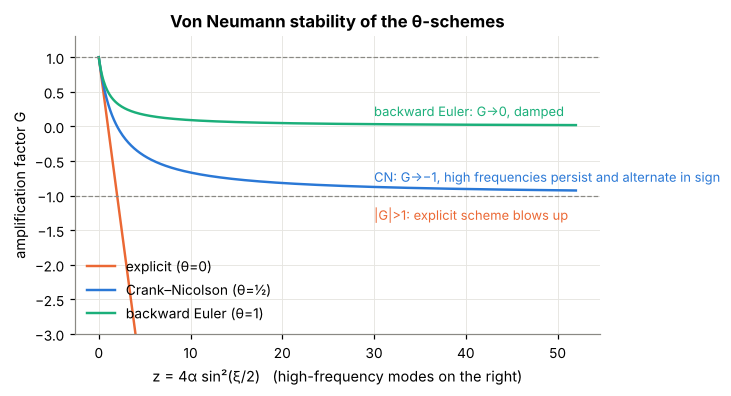

In [ ]:
z = np.linspace(0, 52, 500)       # z = 4*alpha*sin^2(xi/2) ranges over [0, 4*alpha]; alpha is about 13 on a typical production grid
fig, ax = plt.subplots(figsize=(6.6, 3.7))
for th, lab, c in [(0.0, "explicit (θ=0)", PAL[1]), (0.5, "Crank–Nicolson (θ=½)", PAL[0]), (1.0, "backward Euler (θ=1)", PAL[2])]:
    ax.plot(z, (1 - (1 - th)*z)/(1 + th*z), color=c, label=lab)
ax.axhline(1, color="#8a8984", lw=0.8, ls="--"); ax.axhline(-1, color="#8a8984", lw=0.8, ls="--")
ax.set_ylim(-3, 1.3); ax.set_xlabel("z = 4α sin²(ξ/2)   (high-frequency modes on the right)"); ax.set_ylabel("amplification factor G")
ax.set_title("Von Neumann stability of the θ-schemes"); ax.text(30, -1.35, "|G|>1: explicit scheme blows up", color=PAL[1], fontsize=8.5)
ax.text(30, -0.8, "CN: G→−1, high frequencies persist and alternate in sign", color=PAL[0], fontsize=8.5)
ax.text(30, 0.15, "backward Euler: G→0, damped", color=PAL[2], fontsize=8.5); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

## 4. Does the solver give the right answer?
### 4.1 European options: PDE vs closed form
I use a standard at-the-money test case: $S_0=K=100$, $T=1$, $r=5\%$, $\sigma=20\%$. We refine the grid with $N_t=N_x/2$ (so $\Delta\tau\sim\Delta x$, matching CN's 2nd-order behaviour in both) and fit the empirical order of convergence.

In [ ]:
S0, K, T, r, sig = 100.0, 100.0, 1.0, 0.05, 0.20
ref_call = float(bs_price(S0, K, T, r, sig, "call")); ref_put = float(bs_price(S0, K, T, r, sig, "put"))
rows = []
for Nx in [50, 100, 200, 400, 800, 1600]:
    t0 = time.time(); sc = solve_pde(K, T, r, sig, "call", False, Nx=Nx, Nt=Nx//2); dt_ = time.time() - t0
    sp = solve_pde(K, T, r, sig, "put", False, Nx=Nx, Nt=Nx//2)
    rows.append(dict(Nx=Nx, Nt=Nx//2, call=float(sc.value(S0)), call_err=abs(float(sc.value(S0)) - ref_call),
                     put_err=abs(float(sp.value(S0)) - ref_put),
                     delta_err=abs(float(sc.delta(S0)) - float(bs_delta(S0, K, T, r, sig))),
                     gamma_err=abs(float(sc.gamma(S0)) - float(bs_gamma(S0, K, T, r, sig))), secs=dt_))
conv = pd.DataFrame(rows)
order = lambda col: -np.polyfit(np.log(conv.Nx[1:]), np.log(conv[col][1:]), 1)[0]
display(conv.style.format({"call": "{:.6f}", "call_err": "{:.2e}", "put_err": "{:.2e}", "delta_err": "{:.2e}", "gamma_err": "{:.2e}", "secs": "{:.3f}"}).hide(axis="index"))
print(f"closed-form call = {ref_call:.6f}.  Empirical order of convergence in Nx:  price {order('call_err'):.2f},  delta {order('delta_err'):.2f},  gamma {order('gamma_err'):.2f}   (theory: 2)")

Nx,Nt,call,call_err,put_err,delta_err,gamma_err,secs
50,25,10.392450,5.81e-02,6.25e-02,5.00e-04,1.66e-04,1.703
100,50,10.436211,1.44e-02,1.55e-02,1.26e-04,4.03e-05,0.000
200,100,10.447000,3.58e-03,3.86e-03,3.14e-05,9.99e-06,0.001
400,200,10.449688,8.95e-04,9.64e-04,7.86e-06,2.49e-06,0.002
800,400,10.450360,2.24e-04,2.41e-04,1.96e-06,6.23e-07,0.005
1600,800,10.450528,5.59e-05,6.02e-05,4.91e-07,1.56e-07,0.019


closed-form call = 10.450584.  Empirical order of convergence in Nx:  price 2.00,  delta 2.00,  gamma 2.00   (theory: 2)


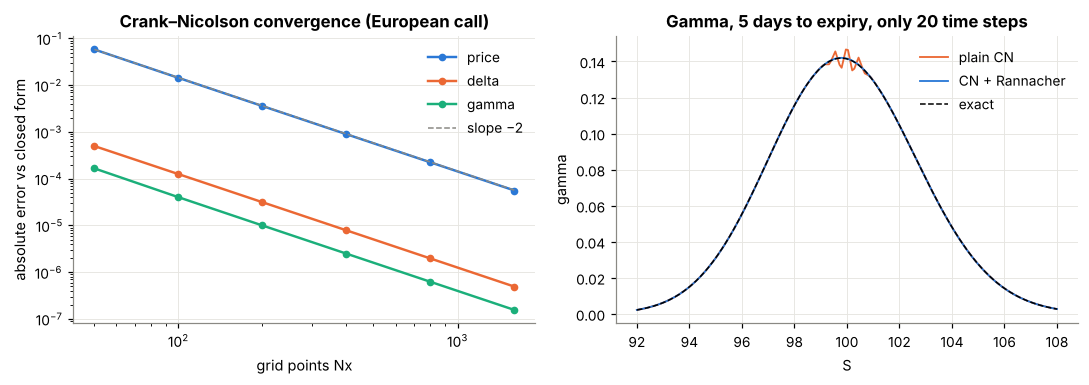

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for col, c, lab in [("call_err", PAL[0], "price"), ("delta_err", PAL[1], "delta"), ("gamma_err", PAL[2], "gamma")]:
    ax[0].loglog(conv.Nx, conv[col], "o-", color=c, ms=4, label=lab)
ax[0].loglog(conv.Nx, conv.call_err.iloc[0]*(conv.Nx/conv.Nx.iloc[0])**-2.0, "--", color="#8a8984", lw=1, label="slope −2")
ax[0].set_xlabel("grid points Nx"); ax[0].set_ylabel("absolute error vs closed form"); ax[0].set_title("Crank–Nicolson convergence (European call)"); ax[0].legend()

# Rannacher: gamma near expiry for a kinked payoff
Tn = 5/252; Ss = np.linspace(92, 108, 200)
exact = bs_gamma(Ss, 100.0, Tn, r, sig)
for rann, c, lab in [(False, PAL[1], "plain CN"), (True, PAL[0], "CN + Rannacher")]:
    sol = solve_pde(100.0, Tn, r, sig, "call", False, Nx=400, Nt=20, rannacher=rann)
    ax[1].plot(Ss, sol.gamma(Ss), color=c, lw=1.2, label=lab)
ax[1].plot(Ss, exact, color="black", lw=1, ls="--", label="exact")
ax[1].set_xlabel("S"); ax[1].set_ylabel("gamma"); ax[1].set_title("Gamma, 5 days to expiry, only 20 time steps"); ax[1].legend()
plt.tight_layout(); plt.show()

The error plot is consistent with second-order convergence for price, delta and gamma. The right panel shows why Rannacher start-up matters: with the payoff kink, plain CN produces
oscillating gamma at coarse time steps, which would feed directly into gamma hedges.

### 4.2 American put: PDE (PSOR) vs binomial vs Longstaff–Schwartz
Test case: $S_0=K=100$, $T=1$, $r=5\%$, $\sigma=20\%$ (American put worth noticeably more than the European one).

In [ ]:
ref_bin = crr_smooth(S0, K, T, r, sig, N=4000)
t0 = time.time(); sol_am = solve_pde(K, T, r, sig, "put", True, Nx=800, Nt=400, record_boundary=True); t_pde = time.time() - t0
t0 = time.time(); lsm_v, lsm_se = lsm_put(S0, K, T, r, sig, M=200_000, steps=50); t_lsm = time.time() - t0
t0 = time.time(); bin1 = crr_smooth(S0, K, T, r, sig, N=1000); t_bin = time.time() - t0
am = pd.DataFrame([
    ("PDE: CN + Rannacher + PSOR (Nx=800, Nt=400)", float(sol_am.value(S0)), "", t_pde),
    ("Binomial CRR, N=4000 (reference)", ref_bin, "", np.nan),
    ("Binomial CRR, N=1000", bin1, "", t_bin),
    ("Longstaff–Schwartz MC (200k paths, 50 dates)", lsm_v, f"± {lsm_se:.3f}", t_lsm),
    ("European put (closed form)", ref_put, "", np.nan)], columns=["method", "American put" , "MC s.e.", "seconds"])
display(am.style.format({"American put": "{:.5f}", "seconds": "{:.2f}"}, na_rep="").hide(axis="index"))
print(f"Early-exercise premium: {float(sol_am.value(S0)) - ref_put:.4f}.   PDE − binomial reference = {float(sol_am.value(S0)) - ref_bin:+.2e};  "
      f"LSM − reference = {lsm_v - ref_bin:+.4f} (LSM is biased low by construction: it uses a sub-optimal exercise rule).")

method,American put,MC s.e.,seconds
"PDE: CN + Rannacher + PSOR (Nx=800, Nt=400)",6.08993,,0.17
"Binomial CRR, N=4000 (reference)",6.09046,,
"Binomial CRR, N=1000",6.09071,,0.07
"Longstaff–Schwartz MC (200k paths, 50 dates)",6.08659,± 0.016,1.04
European put (closed form),5.57353,,


Early-exercise premium: 0.5164.   PDE − binomial reference = -5.28e-04;  LSM − reference = -0.0039 (LSM is biased low by construction: it uses a sub-optimal exercise rule).


Nx,Nt,price,err_vs_binomial,PSOR_sweeps_total,seconds
100,50,6.071083,1.9e-02,661,0.003
200,100,6.085178,5.3e-03,1704,0.009
400,200,6.088898,1.6e-03,4495,0.037
800,400,6.089932,5.3e-04,11803,0.167
1600,800,6.090230,2.3e-04,30988,0.773


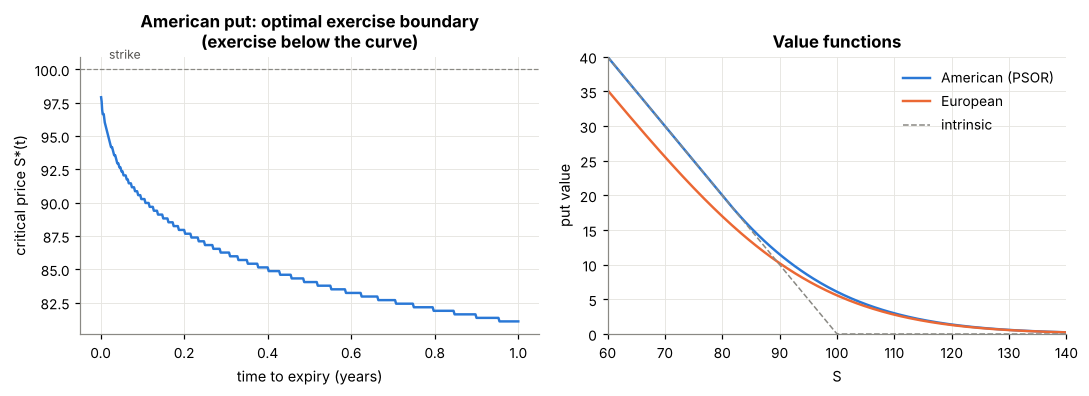

In [ ]:
# PSOR convergence and iteration cost, plus the free boundary
rows = []
for Nx, Nt in [(100, 50), (200, 100), (400, 200), (800, 400), (1600, 800)]:
    t0 = time.time(); s = solve_pde(K, T, r, sig, "put", True, Nx=Nx, Nt=Nt); dt_ = time.time() - t0
    rows.append(dict(Nx=Nx, Nt=Nt, price=float(s.value(S0)), err_vs_binomial=abs(float(s.value(S0)) - ref_bin),
                     PSOR_sweeps_total=s.iters, seconds=dt_))
display(pd.DataFrame(rows).style.format({"price": "{:.6f}", "err_vs_binomial": "{:.1e}", "seconds": "{:.3f}"}).hide(axis="index"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.7))
ax[0].plot(sol_am.tau_grid, sol_am.S_boundary, color=PAL[0])
ax[0].axhline(K, color="#8a8984", lw=0.8, ls="--"); ax[0].text(0.02, K + 0.8, "strike", color=INK2, fontsize=8)
ax[0].set_xlabel("time to expiry (years)"); ax[0].set_ylabel("critical price S*(t)")
ax[0].set_title("American put: optimal exercise boundary\n(exercise below the curve)")
Sg = np.linspace(60, 140, 300)
ax[1].plot(Sg, sol_am.value(Sg), color=PAL[0], label="American (PSOR)")
ax[1].plot(Sg, bs_price(Sg, K, T, r, sig, "put"), color=PAL[1], label="European")
ax[1].plot(Sg, np.maximum(K - Sg, 0), color="#8a8984", lw=1, ls="--", label="intrinsic")
ax[1].set_xlim(60, 140); ax[1].set_ylim(0, 40); ax[1].set_xlabel("S"); ax[1].set_ylabel("put value"); ax[1].set_title("Value functions"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Monte Carlo cross-checks


European call, exact = **10.45058**. Entries: estimate ± standard error.

,plain,antithetic,control,both
"M=1,000",8.8836 ± 0.4187,9.8830 ± 0.3067,9.9537 ± 0.1723,10.4488 ± 0.0839
"M=10,000",10.2280 ± 0.1455,10.3957 ± 0.1029,10.4074 ± 0.0561,10.4575 ± 0.0272
"M=100,000",10.4067 ± 0.0464,10.4160 ± 0.0327,10.4299 ± 0.0177,10.4493 ± 0.0086
"M=1,000,000",10.4452 ± 0.0147,10.4365 ± 0.0104,10.4475 ± 0.0056,10.4492 ± 0.0027


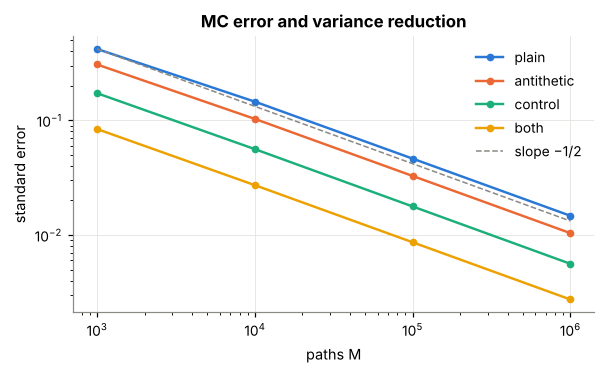

At M = 100,000 the combined antithetic + control-variate estimator has a variance **29× smaller** than plain MC (equivalent to 29× more paths).

In [ ]:
def mc_euro_call(S0, K, T, r, sig, M, method="plain", seed=0):
    """European call by MC. method in {plain, antithetic, control, both}. Returns (price, std. error)."""
    g = np.random.default_rng(seed); disc = math.exp(-r*T)
    anti = method in ("antithetic", "both")
    Z = g.standard_normal(M//2 if anti else M)
    if anti: Z = np.concatenate([Z, -Z])
    ST = S0*np.exp((r - 0.5*sig**2)*T + sig*math.sqrt(T)*Z)
    pay, ctrl = disc*np.maximum(ST - K, 0.0), disc*ST          # E[disc*S_T] = S0 (martingale control)
    if anti:
        h = M//2; pay = 0.5*(pay[:h] + pay[h:]); ctrl = 0.5*(ctrl[:h] + ctrl[h:])
    if method in ("control", "both"):
        beta = np.cov(pay, ctrl)[0, 1]/ctrl.var(ddof=1)
        pay = pay - beta*(ctrl - S0)
    return float(pay.mean()), float(pay.std(ddof=1)/math.sqrt(pay.size))

Ms = [10**3, 10**4, 10**5, 10**6]
methods = ["plain", "antithetic", "control", "both"]
res = {m: [mc_euro_call(100, 100, 1.0, 0.05, 0.2, M, m, seed=7) for M in Ms] for m in methods}
exact = float(bs_price(100, 100, 1.0, 0.05, 0.2, "call"))
tab = pd.DataFrame({m: [f"{p:.4f} ± {s:.4f}" for p, s in res[m]] for m in methods}, index=[f"M={M:,}" for M in Ms])
display(Markdown(f"European call, exact = **{exact:.5f}**. Entries: estimate ± standard error."))
display(tab)
vrf = (res["plain"][2][1]/res["both"][2][1])**2
fig, ax = plt.subplots(figsize=(5.6, 3.5))
for m, c in zip(methods, PAL):
    ax.loglog(Ms, [s for _, s in res[m]], "o-", color=c, ms=4, label=m)
ax.loglog(Ms, res["plain"][0][1]*(np.array(Ms)/Ms[0])**-0.5, "--", color="#8a8984", lw=1, label="slope −1/2")
ax.set_xlabel("paths M"); ax.set_ylabel("standard error"); ax.set_title("MC error and variance reduction"); ax.legend()
plt.tight_layout(); plt.show()
display(Markdown(f"At M = 100,000 the combined antithetic + control-variate estimator has a variance **{vrf:.0f}× smaller** than plain MC (equivalent to {vrf:.0f}× more paths)."))

In [ ]:
def geo_asian_call_exact(S0, K, T, r, sig, n):
    m = math.log(S0) + (r - 0.5*sig**2)*T*(n + 1)/(2*n)
    s2 = sig**2*T*(n + 1)*(2*n + 1)/(6*n**2); s = math.sqrt(s2)
    d1 = (m + s2 - math.log(K))/s; d2 = d1 - s
    return math.exp(-r*T)*(math.exp(m + 0.5*s2)*N_cdf(d1) - K*N_cdf(d2))

def mc_asian(S0, K, T, r, sig, n, M, seed=0):
    g = np.random.default_rng(seed); dt = T/n; disc = math.exp(-r*T)
    Z = g.standard_normal((M//2, n)); Z = np.vstack([Z, -Z])
    S = S0*np.exp(np.cumsum((r - 0.5*sig**2)*dt + sig*math.sqrt(dt)*Z, axis=1))
    arith = disc*np.maximum(S.mean(1) - K, 0); geo = disc*np.maximum(np.exp(np.log(S).mean(1)) - K, 0)
    beta = np.cov(arith, geo)[0, 1]/geo.var(ddof=1)
    cv = arith - beta*(geo - geo_asian_call_exact(S0, K, T, r, sig, n))
    return (arith.mean(), arith.std(ddof=1)/math.sqrt(M)), (cv.mean(), cv.std(ddof=1)/math.sqrt(M)), beta

(p0, s0), (p1, s1), beta = mc_asian(100, 100, 1.0, 0.05, 0.2, 50, 200_000, seed=3)
display(Markdown(f"**Arithmetic Asian call** (50 fixings, 200k paths): plain MC = {p0:.4f} ± {s0:.4f}; with geometric-Asian control variate = {p1:.4f} ± {s1:.4f} "
                 f"(β̂ = {beta:.3f}). Variance reduction ≈ **{(s0/s1)**2:.0f}×**. For reference the European call is worth {exact:.4f}: averaging lowers volatility and hence the option's value."))

**Arithmetic Asian call** (50 fixings, 200k paths): plain MC = 5.8683 ± 0.0182; with geometric-Asian control variate = 5.8581 ± 0.0005 (β̂ = 1.035). Variance reduction ≈ **1312×**. For reference the European call is worth 10.4506: averaging lowers volatility and hence the option's value.

## 6. A hedging check in simulated data
Selling an option at its Black–Scholes price and re-hedging $N$ times with the BS delta leaves a **discrete-hedging error** whose standard deviation falls like $N^{-1/2}$
(Boyle & Emanuel, 1980). Before moving to historical observations, I check that our hedging engine reproduces this law in a world where BS holds exactly, and that hedging with the
**PDE solver's own grid delta** closely matches the analytic delta in this experiment.

P&L (discounted to $t=0$) of the short call: $\;\Pi=C_0+\sum_j\Delta_j e^{-rt_{j+1}}\big(S_{j+1}-e^{r\,dt}S_j\big)-e^{-rT}(S_T-K)^+$.

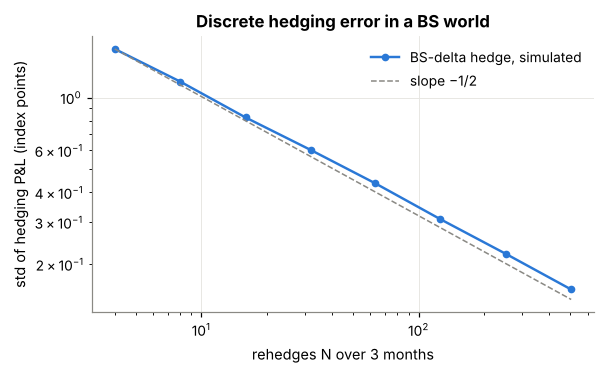

Fitted log–log slope = **-0.480** (theory −0.5). Using the PDE grid delta instead of the analytic delta changes the hedging P&L of each path by at most **2.6e-03** index points (std of the P&L itself: 0.444).

In [ ]:
def hedge_error_gbm(N, paths=6000, T=63/252, r=0.02, sig=0.20, S0=100.0, K=100.0, seed=11, delta_fn=None):
    g = np.random.default_rng(seed); dt = T/N
    Z = g.standard_normal((paths, N))
    S = np.empty((paths, N + 1)); S[:, 0] = S0
    S[:, 1:] = S0*np.exp(np.cumsum((r - 0.5*sig**2)*dt + sig*math.sqrt(dt)*Z, axis=1))
    pnl = np.full(paths, float(bs_price(S0, K, T, r, sig, "call")))
    for j in range(N):
        tau = T - j*dt
        d = bs_delta(S[:, j], K, tau, r, sig, "call") if delta_fn is None else delta_fn(S[:, j], tau)
        pnl += d*math.exp(-r*(j + 1)*dt)*(S[:, j + 1] - math.exp(r*dt)*S[:, j])
    pnl -= math.exp(-r*T)*np.maximum(S[:, -1] - K, 0)
    return pnl

Ns = [4, 8, 16, 32, 63, 126, 252, 504]
errs = np.array([hedge_error_gbm(N).std() for N in Ns])
slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
# Solve once per remaining maturity and reuse the PDE delta across simulated paths.
def pde_delta_fn_factory(K=100.0, r=0.02, sig=0.20):
    cache = {}
    def fn(S, tau):
        key = round(tau, 10)
        if key not in cache: cache[key] = solve_pde(K, max(tau, 1e-4), r, sig, "call", False, Nx=400, Nt=60)
        return cache[key].delta(S)
    return fn
e_bs = hedge_error_gbm(63, paths=3000, seed=5); e_pde = hedge_error_gbm(63, paths=3000, seed=5, delta_fn=pde_delta_fn_factory())
fig, ax = plt.subplots(figsize=(5.6, 3.5))
ax.loglog(Ns, errs, "o-", color=PAL[0], ms=4, label="BS-delta hedge, simulated")
ax.loglog(Ns, errs[0]*(np.array(Ns)/Ns[0])**-0.5, "--", color="#8a8984", lw=1, label="slope −1/2")
ax.set_xlabel("rehedges N over 3 months"); ax.set_ylabel("std of hedging P&L (index points)"); ax.set_title("Discrete hedging error in a BS world"); ax.legend()
plt.tight_layout(); plt.show()
display(Markdown(f"Fitted log–log slope = **{slope:.3f}** (theory −0.5). Using the PDE grid delta instead of the analytic delta changes the hedging P&L of each path by at most "
                 f"**{np.abs(e_bs - e_pde).max():.1e}** index points (std of the P&L itself: {e_bs.std():.3f})."))

## 7. Constructing the option book
I use a small premium-selling portfolio, measured per index unit. Its exposure is mostly short gamma and short vega: it can earn premium when markets are quiet but is vulnerable to sharp moves and volatility increases.

| Position | Style | Strike / S₀ | Quantity |
|---|---|---|---|
| Short ATM call | European | 100% | −1 |
| Short OTM put | **American** (priced with the PSOR solver) | 95% | −1 |
| Long OTM call (cap) | European | 105% | +1 |

All have 63 trading days (≈3 months) to expiry at the start of each cycle. We hold the book for a **21-trading-day horizon** (≈1 month), then start a new cycle.

In [ ]:
R_F, M_OPT, H, ND = 0.02, 63, 21, 252
BOOK = [dict(name="Short ATM call (Eur)", kind="call", am=False, kr=1.00, q=-1.0),
        dict(name="Short 95% put (Amer)", kind="put", am=True, kr=0.95, q=-1.0),
        dict(name="Long 105% call (Eur)", kind="call", am=False, kr=1.05, q=+1.0)]
PDE_NX, PDE_NT = 300, 60

def pos_state(pos, S, K0, m, sig):
    """value, delta, gamma of ONE unit of the position (before multiplying by q). m = trading days to expiry."""
    K = pos["kr"]*K0; T = m/ND
    if not pos["am"]:
        return float(bs_price(S, K, T, R_F, sig, pos["kind"])), float(bs_delta(S, K, T, R_F, sig, pos["kind"])), float(bs_gamma(S, K, T, R_F, sig))
    sol = solve_pde(K, T, R_F, sig, "put", True, Nx=PDE_NX, Nt=PDE_NT)
    return float(sol.value(S)), float(sol.delta(S)), float(sol.gamma(S))

def book_state(S, K0, m, sig, book=BOOK):
    v = d = g = 0.0
    for pos in book:
        a, b, c = pos_state(pos, S, K0, m, sig); v += pos["q"]*a; d += pos["q"]*b; g += pos["q"]*c
    return v, d, g

def book_vega(S, K0, m, sig, book=BOOK, eps=0.005):
    """Vega per 1.00 vol (multiply by 0.01 for per vol point). Closed form for Europeans, central PDE bump for the American put."""
    tot = 0.0
    for pos in book:
        K = pos["kr"]*K0; T = m/ND
        if not pos["am"]: vg = float(bs_vega(S, K, T, R_F, sig))
        else: vg = (pos_state(pos, S, K0, m, sig + eps)[0] - pos_state(pos, S, K0, m, sig - eps)[0])/(2*eps)
        tot += pos["q"]*vg
    return tot

# Accuracy of the production grid (Nx=300, Nt=60) used inside the daily loop vs a very fine grid
rows = []
for sg in [0.12, 0.20, 0.40, 0.80]:
    for m in [63, 21]:
        f = solve_pde(95.0, m/ND, R_F, sg, "put", True, Nx=300, Nt=60); fine = solve_pde(95.0, m/ND, R_F, sg, "put", True, Nx=3200, Nt=1600)
        for S_ in [90.0, 100.0, 110.0]:
            rows.append(dict(sigma=sg, days=m, S=S_, price_err=abs(float(f.value(S_)) - float(fine.value(S_))),
                             delta_err=abs(float(f.delta(S_)) - float(fine.delta(S_))), gamma_err=abs(float(f.gamma(S_)) - float(fine.gamma(S_)))))
grid_chk = pd.DataFrame(rows)
display(Markdown(f"**Production-grid check** (American 95% put, Nx=300, Nt=60 vs Nx=3200, Nt=1600; {len(grid_chk)} cases): "
                 f"max price error {grid_chk.price_err.max():.1e} (index points on S=100), max delta error {grid_chk.delta_err.max():.1e}, max gamma error {grid_chk.gamma_err.max():.1e}."))

**Production-grid check** (American 95% put, Nx=300, Nt=60 vs Nx=3200, Nt=1600; 24 cases): max price error 2.9e-03 (index points on S=100), max delta error 1.8e-04, max gamma error 2.6e-04.

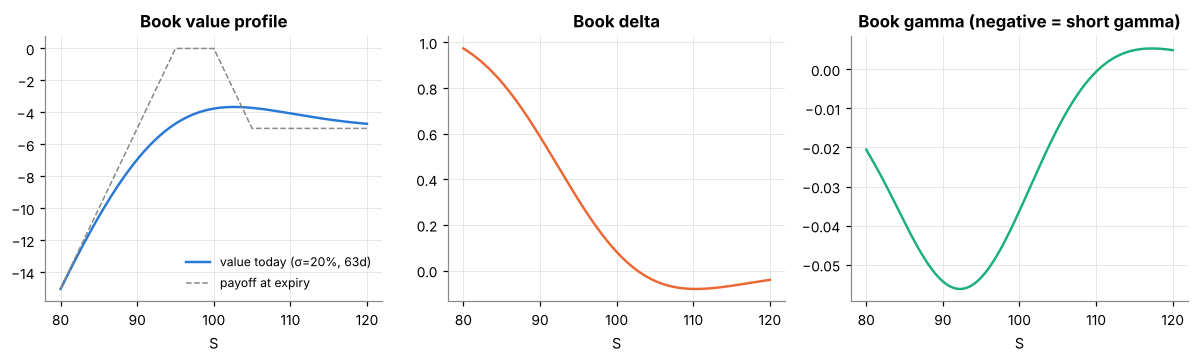

At S=100, σ=20%: book value = **-3.761** (we receive net premium 3.761), delta = **0.082**, gamma = **-0.0362**, vega = **-0.180 per vol point**.

In [ ]:
Sg = np.linspace(80, 120, 161); K0 = 100.0
vals = np.array([book_state(s, K0, M_OPT, 0.20)[0] for s in Sg]); dels = np.array([book_state(s, K0, M_OPT, 0.20)[1] for s in Sg])
gams = np.array([book_state(s, K0, M_OPT, 0.20)[2] for s in Sg])
payoff = -np.maximum(Sg - K0, 0) - np.maximum(0.95*K0 - Sg, 0) + np.maximum(Sg - 1.05*K0, 0)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
ax[0].plot(Sg, vals, color=PAL[0], label="value today (σ=20%, 63d)"); ax[0].plot(Sg, payoff, color="#8a8984", ls="--", lw=1, label="payoff at expiry")
ax[0].set_title("Book value profile"); ax[0].set_xlabel("S"); ax[0].legend(fontsize=8)
ax[1].plot(Sg, dels, color=PAL[1]); ax[1].set_title("Book delta"); ax[1].set_xlabel("S")
ax[2].plot(Sg, gams, color=PAL[2]); ax[2].set_title("Book gamma (negative = short gamma)"); ax[2].set_xlabel("S")
plt.tight_layout(); plt.show()
v0, d0, g0 = book_state(100.0, K0, M_OPT, 0.20); vg0 = book_vega(100.0, K0, M_OPT, 0.20)
display(Markdown(f"At S=100, σ=20%: book value = **{v0:.3f}** (we receive net premium {-v0:.3f}), delta = **{d0:.3f}**, gamma = **{g0:.4f}**, vega = **{vg0*0.01:.3f} per vol point**."))

## 8. Hedging on historical S&P 500 observations



5030 trading days, 1999-01-04 -> 2018-12-31; daily-return skew -0.20, excess kurtosis 8.2


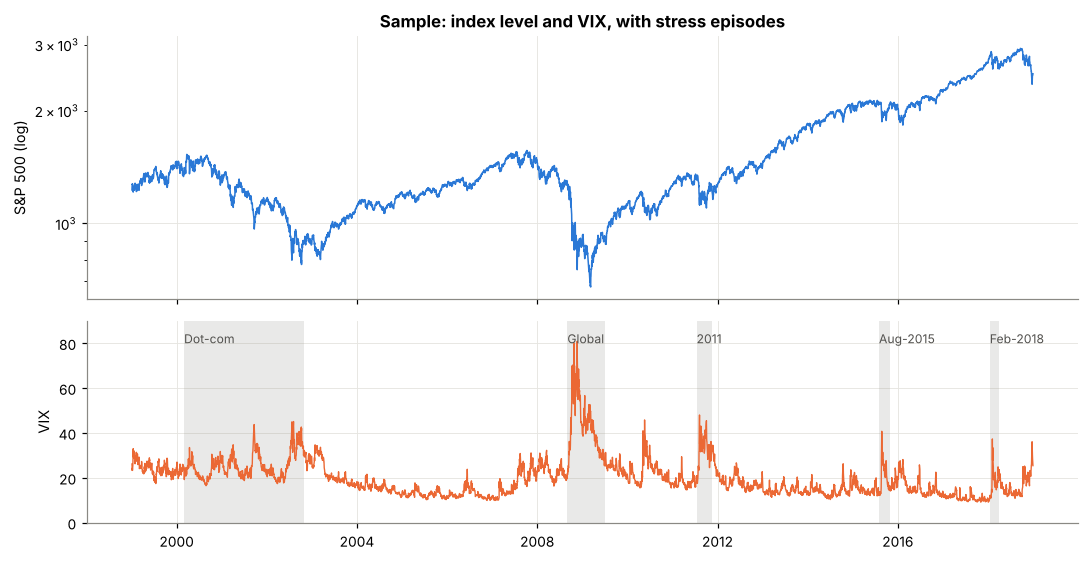

In [ ]:

DATA = "../data" if os.path.isdir("../data") else "data"
os.makedirs(DATA, exist_ok=True)


def load_spx():
    path = f"{DATA}/spx.csv"
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=True)["Close"]

    from arch.data import sp500

    closes = sp500.load()["Close"]
    closes.to_csv(path)
    return closes


def load_vix():
    path = f"{DATA}/vix.csv"
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=True)["CLOSE"]

    url = "https://raw.githubusercontent.com/datasets/finance-vix/main/data/vix-daily.csv"
    closes = pd.read_csv(url, index_col=0, parse_dates=True)["CLOSE"]
    closes.to_csv(path)
    return closes


dfm = pd.concat({"S": load_spx(), "VIX": load_vix()}, axis=1, sort=True).dropna()
S_arr, VIX_arr, dates = dfm.S.values, dfm.VIX.values, dfm.index
R_arr = np.r_[np.nan, np.diff(np.log(S_arr))]
RV63 = pd.Series(R_arr).rolling(63).std().values * np.sqrt(ND)
print(
    f"{len(dfm)} trading days, {dates[0].date()} -> {dates[-1].date()}; "
    f"daily-return skew {stats.skew(R_arr[1:]):.2f}, "
    f"excess kurtosis {stats.kurtosis(R_arr[1:]):.1f}"
)

EPISODES = {
    "Dot-com bust": ("2000-03-01", "2002-10-31"),
    "Global financial crisis": ("2008-09-01", "2009-06-30"),
    "2011 US downgrade": ("2011-07-15", "2011-11-15"),
    "Aug-2015 China scare": ("2015-08-01", "2015-10-31"),
    "Feb-2018 'Volmageddon'": ("2018-01-15", "2018-03-31"),
}

fig, ax = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True,
                       gridspec_kw={"height_ratios": [1.3, 1]})
ax[0].plot(dates, S_arr, color=PAL[0], lw=1.0)
ax[0].set_yscale("log")
ax[0].set_ylabel("S&P 500 (log)")
ax[0].set_title("Sample: index level and VIX, with stress episodes")
ax[1].plot(dates, VIX_arr, color=PAL[1], lw=0.9)
ax[1].set_ylabel("VIX")
ax[1].set_ylim(0, 90)

for name, (start, end) in EPISODES.items():
    ax[1].axvspan(pd.Timestamp(start), pd.Timestamp(end),
                  color="#8a8984", alpha=0.18, lw=0)
    ax[1].text(pd.Timestamp(start), 80, name.split()[0], fontsize=8, color=INK2)

plt.tight_layout()
plt.show()

### 8.2 Experiment setup
* **Cycles.** Every 21 trading days we write the book of §7 (K₀ = S at origin), hold it 21 days, and mark it at the end with the 42-day-remaining options. The windows do not overlap, but that does not guarantee independence: common market regimes can affect successive cycles.
* **Marks.** Every option is valued with the §3 solvers using flat σ = VIX/100 on that day. The hedger sees the same marks, so P&L includes **gamma (path), theta, and vega (ΔVIX) effects**, under this simplified marking convention.
* **Hedge strategies** (all start delta-hedged at the origin, rebalanced at the close; stock financed at r):

* **Costs.** Stock: 5 bp of traded notional; options: 2 % of the premium traded (half spread), paid at opening and at the horizon. The main comparison uses **gross** (before-cost) P&L, and costs are examined separately.
* **Regimes.** Each cycle is labelled by VIX at its origin: *calm* < 20, *elevated* 20–30, *stress* ≥ 30.

In [ ]:
TC_S, TC_O = 0.0005, 0.02
M_I1, M_I2 = 42, 126            # maturities (trading days) of the ATM hedging calls at the origin: 2 months and 6 months
n_all = list(range(63, len(S_arr) - H, H))
origins = n_all[::5] if QUICK else n_all

def build_cycle(d0):
    idx = np.arange(d0, d0 + H + 1)
    S = S_arr[idx]; sV = VIX_arr[idx]/100.0; sR = np.maximum(RV63[idx], 0.05); K0 = S[0]
    V = np.empty(H + 1); D = np.empty(H + 1); G = np.empty(H + 1); DR = np.empty(H + 1)
    I1 = np.empty(H + 1); I1D = np.empty(H + 1); I2 = np.empty(H + 1); I2D = np.empty(H + 1)
    for j in range(H + 1):
        m = M_OPT - j
        V[j], D[j], G[j] = book_state(S[j], K0, m, sV[j])
        DR[j] = book_state(S[j], K0, m, sR[j])[1]
        T1, T2 = (M_I1 - j)/ND, (M_I2 - j)/ND
        I1[j] = bs_price(S[j], K0, T1, R_F, sV[j], "call"); I1D[j] = bs_delta(S[j], K0, T1, R_F, sV[j], "call")
        I2[j] = bs_price(S[j], K0, T2, R_F, sV[j], "call"); I2D[j] = bs_delta(S[j], K0, T2, R_F, sV[j], "call")
    T1, T2 = M_I1/ND, M_I2/ND
    return dict(d0=d0, date=dates[d0], S=S, sV=sV, sR=sR, V=V, D=D, G=G, DR=DR, I1=I1, I1D=I1D, I2=I2, I2D=I2D,
                g_I1=float(bs_gamma(S[0], K0, T1, R_F, sV[0])), g_I2=float(bs_gamma(S[0], K0, T2, R_F, sV[0])),
                v_I1=float(bs_vega(S[0], K0, T1, R_F, sV[0])), v_I2=float(bs_vega(S[0], K0, T2, R_F, sV[0])),
                vega_book=book_vega(S[0], K0, M_OPT, sV[0]), vix0=VIX_arr[d0], vixH=VIX_arr[d0 + H])

t0 = time.time()
cycles = [build_cycle(d) for d in origins]
print(f"{len(cycles)} monthly cycles built ({len(cycles)*(H+1)*2} PDE solves) in {time.time() - t0:.1f}s")

236 monthly cycles built (10384 PDE solves) in 103.5s


In [ ]:
STRATS = [("unh", "Unhedged"), ("stat", "Static delta"), ("dd", "Daily delta (VIX σ)"), ("ddr", "Daily delta (realized σ)"),
          ("dg", "Delta + static gamma"), ("dgv", "Delta + static gamma & vega")]
SCOL = dict(zip([s for s, _ in STRATS], PAL))
SNAME = dict(STRATS)

def cycle_pnl(cy, strat, tc_s=0.0, tc_o=0.0, freq=1):
    """P&L over the 21-day horizon in index points. Positive = gain."""
    S = cy["S"]; ex = S[1:] - S[:-1]*math.exp(R_F/ND)            # excess stock return per day (H entries)
    dV = cy["V"][-1] - cy["V"][0]                                   # book mark-to-market change
    if strat == "unh": return dV
    j = np.arange(H); idx = (j//freq)*freq                          # rebalance every `freq` days
    n1 = n2 = 0.0
    if strat == "stat":  h = np.full(H, -cy["D"][0])
    elif strat == "dd":  h = -cy["D"][:H][idx]
    elif strat == "ddr": h = -cy["DR"][:H][idx]
    elif strat in ("dg", "dgv"):
        if strat == "dg": n1 = -cy["G"][0]/cy["g_I1"]
        else:
            n1, n2 = np.linalg.solve([[cy["g_I1"], cy["g_I2"]], [cy["v_I1"], cy["v_I2"]]], [-cy["G"][0], -cy["vega_book"]])
        h = -((cy["D"][:H] + n1*cy["I1D"][:H] + n2*cy["I2D"][:H])[idx])
    gain = float((h*ex).sum()) + n1*(cy["I1"][-1] - cy["I1"][0]) + n2*(cy["I2"][-1] - cy["I2"][0])
    cost = tc_s*(S[0]*abs(h[0]) + float((S[1:H]*np.abs(np.diff(h))).sum()) + S[H]*abs(h[-1]))
    cost += tc_o*(abs(n1)*(cy["I1"][0] + cy["I1"][-1]) + abs(n2)*(cy["I2"][0] + cy["I2"][-1]))
    return dV + gain - cost

def pnl_table(tc_s=0.0, tc_o=0.0, freq=1):
    """cycles x strategies array, in % of the origin index level."""
    return pd.DataFrame({SNAME[s]: [100*cycle_pnl(cy, s, tc_s, tc_o, freq)/cy["S"][0] for cy in cycles] for s, _ in STRATS})

meta = pd.DataFrame(dict(date=[c["date"] for c in cycles], vix0=[c["vix0"] for c in cycles], vixH=[c["vixH"] for c in cycles],
                         ret=[100*(c["S"][-1]/c["S"][0] - 1) for c in cycles]))
meta["regime"] = pd.cut(meta.vix0, [0, 20, 30, 200], labels=["calm (<20)", "elevated (20-30)", "stress (≥30)"], right=False)
meta["dVIX"] = meta.vixH - meta.vix0
P = pnl_table()                      # gross P&L
PN = pnl_table(TC_S, TC_O)           # net P&L
print(meta.regime.value_counts().reindex(["calm (<20)", "elevated (20-30)", "stress (≥30)"]).to_string())

regime
calm (<20)          136
elevated (20-30)     77
stress (≥30)         23


### 8.3 Comparing the hedge strategies
Metrics per strategy over all cycles, in **% of the index level at the origin** (so a −3 means a loss of 3 % of notional): mean P&L, standard deviation (the *hedging error*),
**5 % CVaR** (average of the worst 5 % of cycles), the worst cycle, and **hedge effectiveness** = 1 − Var(hedged)/Var(unhedged).

In [ ]:
def cvar(x, q=0.05):
    """Mean P&L in the worst q fraction of observations."""
    ordered = np.sort(np.asarray(x))
    n_tail = max(int(np.ceil(q * len(ordered))), 1)
    return ordered[:n_tail].mean()

def summarize(Pm, mask=None):
    Pm = Pm if mask is None else Pm[mask]
    base = Pm["Unhedged"].var()
    return pd.DataFrame({"mean": Pm.mean(), "std (hedging error)": Pm.std(), "5% CVaR": Pm.apply(cvar), "worst": Pm.min(),
                         "hedge effectiveness": 1 - Pm.var()/base}).round(3)

display(Markdown(f"**All {len(P)} cycles, gross of costs.**")); overall = summarize(P); display(overall)

**All 236 cycles, gross of costs.**

,mean,std (hedging error),5% CVaR,worst,hedge effectiveness
Unhedged,0.089,1.854,-4.960,-20.741,0.000
Static delta,0.075,1.474,-3.903,-16.653,0.368
Daily delta (VIX σ),-0.056,0.981,-2.918,-9.214,0.720
Daily delta (realized σ),-0.035,1.272,-3.959,-8.506,0.529
Delta + static gamma,-0.279,0.478,-1.779,-4.969,0.934
Delta + static gamma & vega,-0.281,0.281,-1.122,-2.516,0.977


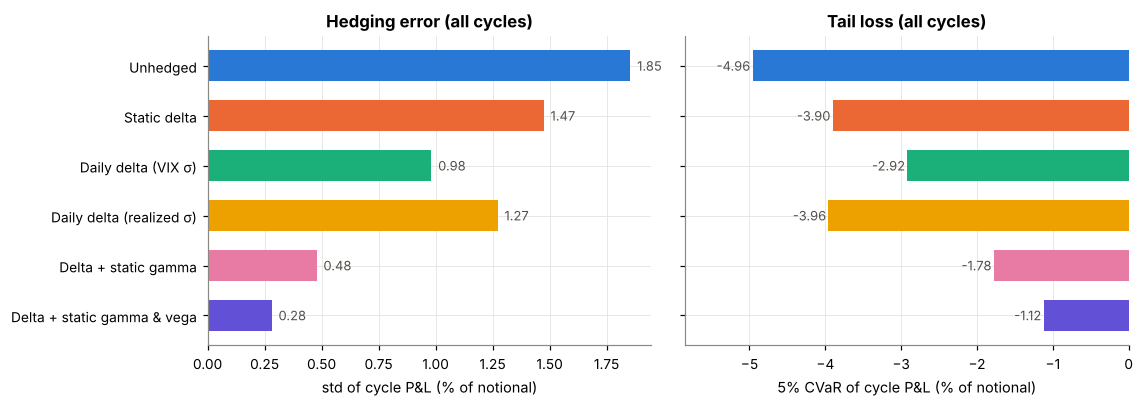

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
names = [SNAME[s] for s, _ in STRATS]
ax[0].barh(names[::-1], overall["std (hedging error)"].values[::-1], color=[SCOL[s] for s, _ in STRATS][::-1], height=0.62)
ax[0].set_xlabel("std of cycle P&L (% of notional)"); ax[0].set_title("Hedging error (all cycles)")
for i, v in enumerate(overall["std (hedging error)"].values[::-1]): ax[0].text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
ax[1].barh(names[::-1], overall["5% CVaR"].values[::-1], color=[SCOL[s] for s, _ in STRATS][::-1], height=0.62)
ax[1].set_xlabel("5% CVaR of cycle P&L (% of notional)"); ax[1].set_title("Tail loss (all cycles)")
for i, v in enumerate(overall["5% CVaR"].values[::-1]): ax[1].text(v - 0.03, i, f"{v:.2f}", va="center", ha="right", fontsize=8.5, color=INK2)
ax[1].set_xlim(left=overall["5% CVaR"].min()*1.18); ax[1].set_yticklabels([]); plt.tight_layout(); plt.show()

### 8.4 Splitting the sample by the starting VIX
The same table by VIX regime at the origin. The key question is whether the hedges that look adequate on average **fail precisely when risk is highest**.

In [ ]:
reg_tabs = {}
for rg in ["calm (<20)", "elevated (20-30)", "stress (≥30)"]:
    m = (meta.regime == rg).values; reg_tabs[rg] = summarize(P, m)
    display(Markdown(f"**{rg}: {m.sum()} cycles**")); display(reg_tabs[rg][["mean", "std (hedging error)", "5% CVaR", "worst", "hedge effectiveness"]])

**calm (<20): 136 cycles**

,mean,std (hedging error),5% CVaR,worst,hedge effectiveness
Unhedged,-0.144,0.844,-2.743,-6.261,0.000
Static delta,-0.121,0.822,-2.843,-5.366,0.051
Daily delta (VIX σ),-0.189,0.752,-2.612,-4.337,0.205
Daily delta (realized σ),-0.186,1.189,-4.051,-5.819,-0.986
Delta + static gamma,-0.307,0.408,-1.685,-2.942,0.766
Delta + static gamma & vega,-0.248,0.255,-1.053,-1.853,0.909


**elevated (20-30): 77 cycles**

,mean,std (hedging error),5% CVaR,worst,hedge effectiveness
Unhedged,0.079,2.728,-8.261,-20.741,0.000
Static delta,0.116,2.136,-6.071,-16.653,0.387
Daily delta (VIX σ),0.000,1.275,-3.632,-9.214,0.782
Daily delta (realized σ),0.012,1.406,-4.043,-8.506,0.735
Delta + static gamma,-0.290,0.611,-2.057,-4.969,0.950
Delta + static gamma & vega,-0.319,0.328,-1.262,-2.516,0.986


**stress (≥30): 23 cycles**

,mean,std (hedging error),5% CVaR,worst,hedge effectiveness
Unhedged,1.501,2.058,-3.737,-6.066,0.000
Static delta,1.093,1.412,-2.029,-2.632,0.529
Daily delta (VIX σ),0.549,0.832,-0.842,-0.850,0.837
Daily delta (realized σ),0.705,1.030,-1.454,-2.009,0.749
Delta + static gamma,-0.081,0.292,-0.629,-0.740,0.980
Delta + static gamma & vega,-0.348,0.238,-0.860,-1.050,0.987


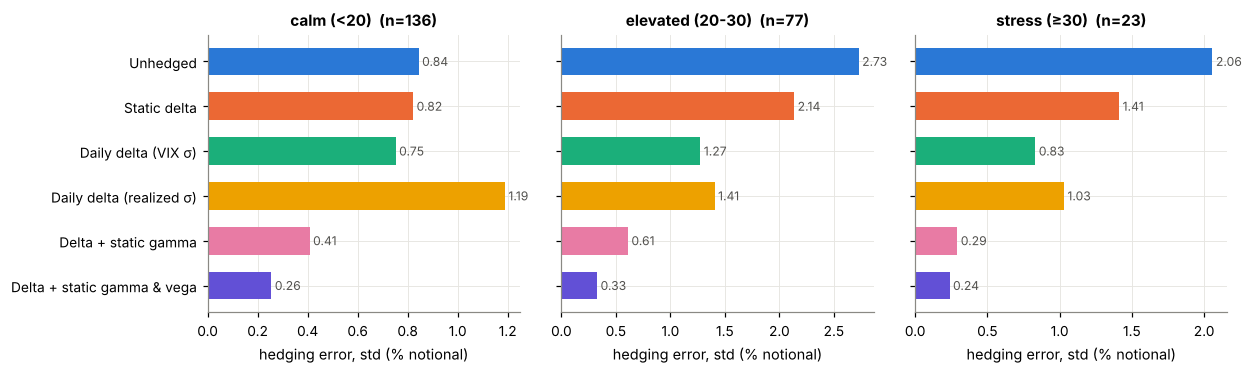

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.5), sharey=False)
for a, rg in zip(ax, reg_tabs):
    t = reg_tabs[rg]; a.barh(names[::-1], t["std (hedging error)"].values[::-1], color=[SCOL[s] for s, _ in STRATS][::-1], height=0.62)
    a.set_title(f"{rg}  (n={(meta.regime == rg).sum()})", fontsize=10); a.set_xlabel("hedging error, std (% notional)")
    for i, v in enumerate(t["std (hedging error)"].values[::-1]): a.text(v, i, f" {v:.2f}", va="center", fontsize=8, color=INK2)
    if a is not ax[0]: a.set_yticklabels([])
plt.tight_layout(); plt.show()

### 8.5 Understanding what delta hedging leaves behind
A delta hedge removes first-order spot risk. What is left in a short-gamma, short-vega book is (i) **gamma/theta** (path-dependent, small over a month) and
(ii) **vega**: the book is marked at VIX, so when VIX jumps, the marks move even if the index is flat. Regress each strategy's cycle P&L on the change in VIX over the cycle.

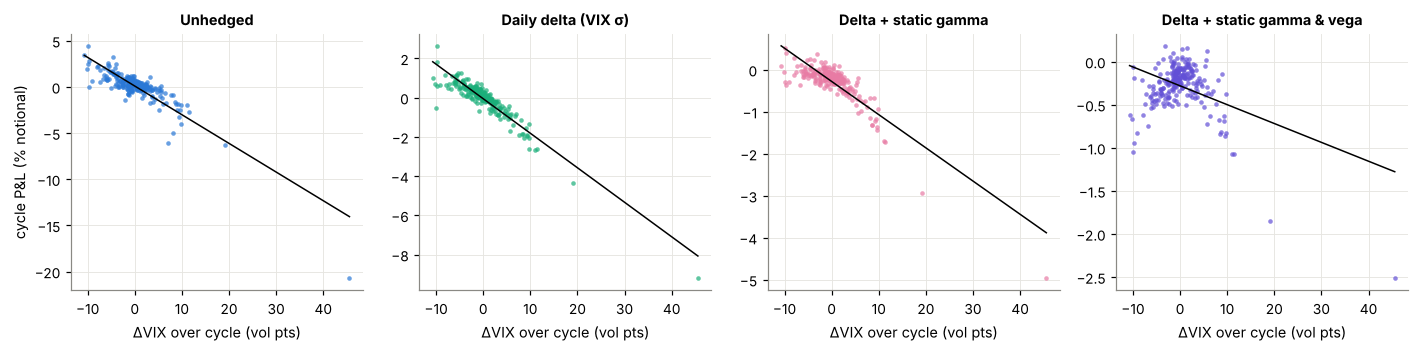

,P&L per +1 VIX pt (% notional),R² of regression on ΔVIX
strategy,,
Unhedged,-0.310,0.754
Daily delta (VIX σ),-0.176,0.866
Delta + static gamma,-0.079,0.736
Delta + static gamma & vega,-0.022,0.164


In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.3), sharex=True)
reg_rows = []
for a, (s, nm) in zip(ax, [(s, n) for s, n in STRATS if s in ("unh", "dd", "dg", "dgv")]):
    y = P[nm].values; x = meta.dVIX.values
    sl, ic, rr, pv, se = stats.linregress(x, y)
    a.scatter(x, y, s=9, color=SCOL[s], alpha=0.7, lw=0); xs = np.array([x.min(), x.max()]); a.plot(xs, ic + sl*xs, color="black", lw=1)
    a.set_title(nm, fontsize=9.5); a.set_xlabel("ΔVIX over cycle (vol pts)")
    reg_rows.append(dict(strategy=nm, **{"P&L per +1 VIX pt (% notional)": sl, "R² of regression on ΔVIX": rr**2}))
ax[0].set_ylabel("cycle P&L (% notional)"); plt.tight_layout(); plt.show()
display(pd.DataFrame(reg_rows).round(3).set_index("strategy"))

### 8.6 P&L through time and during particular episodes

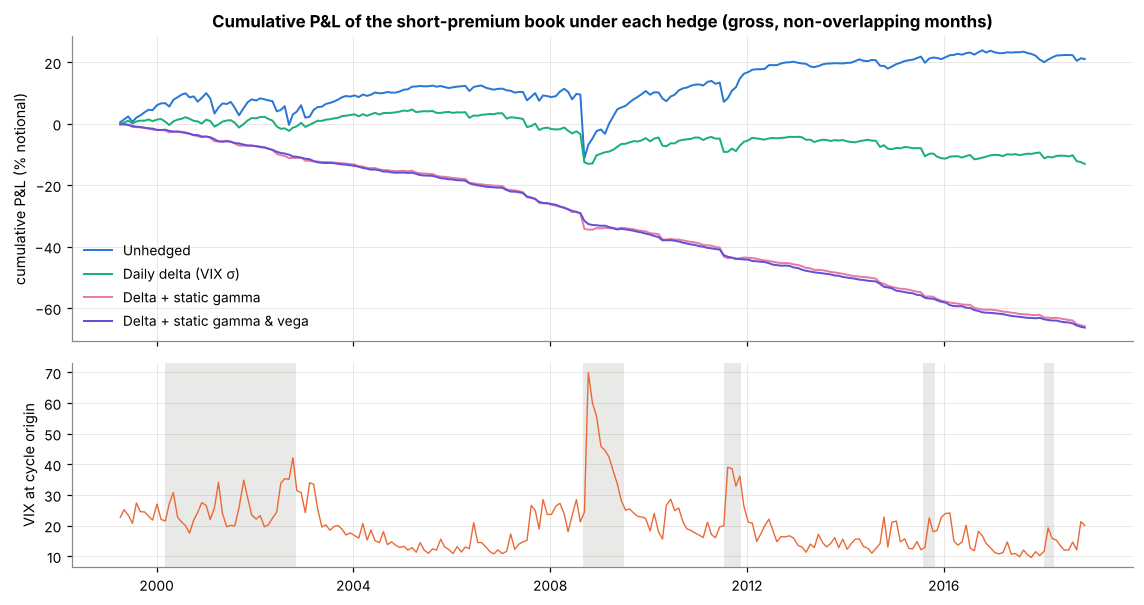

**Total P&L over each stress episode** (sum of monthly cycles whose origin falls in the window, % of notional):

,cycles,"index return (sum of cycles, %)",Unhedged,Static delta,Daily delta (VIX σ),Daily delta (realized σ),Delta + static gamma,Delta + static gamma & vega
episode,,,,,,,,
Dot-com bust,32,-35.80,-3.58,-1.80,-2.84,-7.57,-9.10,-8.63
Global financial crisis,10,-25.58,-4.18,-0.10,-3.25,-0.77,-4.63,-5.13
2011 US downgrade,4,6.91,7.55,6.10,2.04,2.77,-0.52,-1.28
Aug-2015 China scare,3,-2.01,-0.31,-1.06,-1.69,-3.57,-1.42,-1.13
Feb-2018 'Volmageddon',3,-2.48,0.65,0.07,-1.65,-3.68,-1.06,-0.89


In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(10.5, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[1.5, 1]))
for s, nm in STRATS:
    if s in ("unh", "dd", "dg", "dgv"):
        ax[0].plot(meta.date, P[nm].cumsum(), color=SCOL[s], lw=1.3, label=nm)
ax[0].set_ylabel("cumulative P&L (% notional)"); ax[0].set_title("Cumulative P&L of the short-premium book under each hedge (gross, non-overlapping months)"); ax[0].legend(loc="lower left")
ax[1].plot(meta.date, meta.vix0, color=PAL[1], lw=0.9); ax[1].set_ylabel("VIX at cycle origin")
for nm_, (a_, b_) in EPISODES.items(): ax[1].axvspan(pd.Timestamp(a_), pd.Timestamp(b_), color="#8a8984", alpha=0.18, lw=0)
plt.tight_layout(); plt.show()

ep_rows = []
for nm_, (a_, b_) in EPISODES.items():
    m = ((meta.date >= pd.Timestamp(a_)) & (meta.date <= pd.Timestamp(b_))).values
    if m.sum() == 0: continue
    row = {"episode": nm_, "cycles": int(m.sum()), "index return (sum of cycles, %)": meta.ret[m].sum()}
    for s, nm in STRATS: row[nm] = P[nm][m].sum()
    ep_rows.append(row)
display(Markdown("**Total P&L over each stress episode** (sum of monthly cycles whose origin falls in the window, % of notional):"))
display(pd.DataFrame(ep_rows).set_index("episode").round(2))

In [ ]:
wc = P.copy(); wc["origin"] = meta.date.dt.date.values; wc["VIX at origin"] = meta.vix0.values; wc["ΔVIX"] = meta.dVIX.values; wc["index ret %"] = meta.ret.values
worst10 = wc.nsmallest(10, "Unhedged")
display(Markdown("**Ten worst cycles for the unhedged book** (P&L in % of notional):"))
display(worst10[["origin", "VIX at origin", "ΔVIX", "index ret %"] + names].round(2).set_index("origin"))
crash = meta.ret.values <= -8
display(Markdown(f"**All {crash.sum()} cycles with index return ≤ −8 %** (ex-post crash cycles): average and worst P&L."))
display(pd.DataFrame({"mean": P[crash].mean(), "worst": P[crash].min()}).T.round(2))

**Ten worst cycles for the unhedged book** (P&L in % of notional):

,VIX at origin,ΔVIX,index ret %,Unhedged,Static delta,Daily delta (VIX σ),Daily delta (realized σ),Delta + static gamma,Delta + static gamma & vega
origin,,,,,,,,,
2008-09-11,24.39,45.56,-28.01,-20.74,-16.65,-9.21,-8.51,-4.97,-2.52
2011-07-13,19.91,19.09,-11.01,-6.26,-5.37,-4.34,-5.82,-2.94,-1.85
2002-09-10,35.08,7.05,-14.60,-6.07,-2.63,-0.83,-0.90,-0.74,-0.34
2001-03-06,25.89,8.18,-12.01,-4.95,-2.98,-1.84,-2.17,-1.14,-0.68
2003-01-09,24.25,9.74,-9.88,-4.04,-2.61,-1.33,-1.57,-0.93,-0.37
2002-06-11,24.45,9.40,-8.51,-3.31,-2.05,-1.92,-2.55,-1.18,-0.63
2007-07-13,15.15,11.42,-6.41,-2.74,-2.92,-2.62,-3.75,-1.72,-1.08
2007-10-11,18.88,9.62,-6.48,-2.48,-2.07,-2.07,-2.02,-1.43,-0.87
2008-06-12,23.33,5.15,-8.33,-2.47,-1.35,-0.88,-1.29,-0.83,-0.53


**All 8 cycles with index return ≤ −8 %** (ex-post crash cycles): average and worst P&L.

,Unhedged,Static delta,Daily delta (VIX σ),Daily delta (realized σ),Delta + static gamma,Delta + static gamma & vega
mean,-6.16,-4.06,-2.49,-2.83,-1.57,-0.86
worst,-20.74,-16.65,-9.21,-8.51,-4.97,-2.52


### 8.7 How often should the delta hedge be updated?
More frequent rebalancing shrinks hedging error but costs more. We reuse the stored daily deltas, rebalancing every *f* days, and report **gross** and **net-of-cost** results for the daily-delta strategy.

In [ ]:
fr_rows = []
for f_ in [1, 2, 3, 5, 7, 10, 21]:
    g = pd.Series([100*cycle_pnl(cy, "dd", 0, 0, f_)/cy["S"][0] for cy in cycles]); n = pd.Series([100*cycle_pnl(cy, "dd", TC_S, 0, f_)/cy["S"][0] for cy in cycles])
    fr_rows.append(dict(rebalance_every_days=f_, gross_std=g.std(), net_std=n.std(), mean_cost=g.mean() - n.mean(), net_mean=n.mean(), net_5pct_CVaR=cvar(n)))
fr = pd.DataFrame(fr_rows).set_index("rebalance_every_days"); display(fr.round(3))
cost_tab = pd.DataFrame({"gross mean": P.mean(), "net mean": PN.mean(), "cost per cycle": P.mean() - PN.mean(), "gross std": P.std(), "net std": PN.std()}).round(3)
display(Markdown("**Cost of each strategy** (5 bp on stock, 2 % of premium on options, % of notional per cycle):")); display(cost_tab)

,gross_std,net_std,mean_cost,net_mean,net_5pct_CVaR
rebalance_every_days,,,,,
1,0.981,0.989,0.058,-0.114,-3.005
2,1.029,1.036,0.046,-0.084,-3.049
3,1.008,1.012,0.037,-0.038,-3.087
5,1.020,1.024,0.034,-0.025,-2.988
7,1.191,1.194,0.025,-0.006,-3.595
10,1.271,1.276,0.029,0.015,-3.556
21,1.474,1.473,0.011,0.063,-3.913


**Cost of each strategy** (5 bp on stock, 2 % of premium on options, % of notional per cycle):

,gross mean,net mean,cost per cycle,gross std,net std
Unhedged,0.089,0.089,0.000,1.854,1.854
Static delta,0.075,0.063,0.011,1.474,1.473
Daily delta (VIX σ),-0.056,-0.114,0.058,0.981,0.989
Daily delta (realized σ),-0.035,-0.093,0.058,1.272,1.288
Delta + static gamma,-0.279,-0.435,0.156,0.478,0.473
Delta + static gamma & vega,-0.281,-0.498,0.217,0.281,0.309


### 8.8 Uncertainty in the hedge comparisons
To quantify sampling uncertainty, I use a **paired bootstrap over cycles** (5,000 resamples) for the ratio of hedging-error standard deviations.

In [ ]:
def boot_ratio(a, b, B=5000, seed=1):
    g = np.random.default_rng(seed); n = len(a); out = np.empty(B)
    for i in range(B):
        k = g.integers(0, n, n); out[i] = a[k].std(ddof=1)/b[k].std(ddof=1)
    return a.std(ddof=1)/b.std(ddof=1), np.percentile(out, [2.5, 97.5])
cmp = [("Daily delta (VIX σ)", "Unhedged"), ("Daily delta (VIX σ)", "Static delta"), ("Daily delta (realized σ)", "Daily delta (VIX σ)"),
       ("Delta + static gamma", "Daily delta (VIX σ)"), ("Delta + static gamma & vega", "Delta + static gamma")]
brow = []
for a_, b_ in cmp:
    for lab, m in [("all", np.ones(len(P), bool)), ("stress (VIX≥30)", (meta.regime == "stress (≥30)").values)]:
        if m.sum() < 8: continue
        pt, ci = boot_ratio(P[a_].values[m], P[b_].values[m]); brow.append(dict(numerator=a_, denominator=b_, sample=lab, n=int(m.sum()), std_ratio=pt, ci_low=ci[0], ci_high=ci[1], significant=bool(ci[1] < 1 or ci[0] > 1)))
boot_df = pd.DataFrame(brow); display(boot_df.round(3))

,numerator,denominator,sample,n,std_ratio,ci_low,ci_high,significant
0,Daily delta (VIX σ),Unhedged,all,236,0.529,0.471,0.695,True
1,Daily delta (VIX σ),Unhedged,stress (VIX≥30),23,0.404,0.250,0.927,True
2,Daily delta (VIX σ),Static delta,all,236,0.665,0.595,0.842,True
3,Daily delta (VIX σ),Static delta,stress (VIX≥30),23,0.589,0.406,0.925,True
4,Daily delta (realized σ),Daily delta (VIX σ),all,236,1.296,1.125,1.543,True
5,Daily delta (realized σ),Daily delta (VIX σ),stress (VIX≥30),23,1.239,0.958,1.596,False
6,Delta + static gamma,Daily delta (VIX σ),all,236,0.487,0.431,0.515,True
7,Delta + static gamma,Daily delta (VIX σ),stress (VIX≥30),23,0.351,0.295,0.428,True
8,Delta + static gamma & vega,Delta + static gamma,all,236,0.587,0.530,0.718,True
9,Delta + static gamma & vega,Delta + static gamma,stress (VIX≥30),23,0.815,0.453,1.358,False


## 9. Does one-day VaR capture the remaining risk?
I compare three ways of estimating the 1-day 99 % VaR of the option book. Three methods:

1. **Delta-normal**: $\mathrm{VaR}=2.326\,|\Delta|\,S\,\hat\sigma$ (linear in the spot move).
2. **Delta–gamma (quadratic) simulation**: $\Delta P\approx\Delta S\varepsilon+\tfrac12\Gamma S^2\varepsilon^2$ with Gaussian $\varepsilon$.
3. **Filtered historical simulation (FHS), full revaluation**: take the last 500 standardised returns $z_s=R_s/\hat\sigma_s$ (EWMA, λ = 0.94), rescale by today's $\hat\sigma$, and **re-price the whole book** (including the American put, via the PDE solver) at each scenario one day closer to expiry. This also captures higher-order terms and time decay; it reports Expected Shortfall (ES) too.

We back-test each against the realised next-day P&L of (a) the **unhedged book** and (b) the **delta-hedged book** (after re-hedging, the position has zero delta, so only gamma risk remains). A well-calibrated 99 % VaR is exceeded on 1 % of days; the **Kupiec POF test** tests that rate.



In [ ]:
LAM = 0.94
evar = np.full(len(S_arr), np.nan); v_ = np.var(R_arr[1:101])
for d in range(1, len(S_arr)):
    v_ = LAM*v_ + (1 - LAM)*R_arr[d]**2; evar[d] = v_           # evar[d] = variance forecast for day d+1, known at close of day d
zres = np.full(len(S_arr), np.nan)
zres[2:] = R_arr[2:]/np.sqrt(evar[1:-1])                         # standardised return of day d
Zn = np.random.default_rng(99).standard_normal(20000)
Z99 = stats.norm.ppf(0.99)

def book_vec(S_vec, K0, m, sig):
    tot = np.zeros_like(S_vec)
    for pos in BOOK:
        K = pos["kr"]*K0; T = m/ND
        if pos["am"]: v = solve_pde(K, T, R_F, sig, "put", True, Nx=PDE_NX, Nt=PDE_NT).value(S_vec)
        else: v = bs_price(S_vec, K, T, R_F, sig, pos["kind"])
        tot = tot + pos["q"]*v
    return tot

recs = []
t0 = time.time()
for cy in cycles:
    K0 = cy["S"][0]
    for j in range(H):
        d = cy["d0"] + j
        if d < 252: continue
        S0_, S1_, sg = cy["S"][j], cy["S"][j + 1], cy["sV"][j]; m1 = M_OPT - j - 1
        se = math.sqrt(evar[d]); zs = zres[max(2, d - 499):d + 1]
        Sscn = S0_*np.exp(se*zs)
        vals = book_vec(np.r_[S1_, Sscn], K0, m1, sg)
        act, scn = vals[0] - cy["V"][j], vals[1:] - cy["V"][j]
        D, G = cy["D"][j], cy["G"][j]; carry = S0_*math.exp(R_F/ND)
        for book, (a_, s_, Dd) in {"unhedged": (act, scn, D), "delta-hedged": (act - D*(S1_ - carry), scn - D*(Sscn - carry), 0.0)}.items():
            pdg = Dd*S0_*se*Zn + 0.5*G*S0_**2*se**2*Zn**2
            q = np.quantile(s_, 0.01)
            recs.append(dict(date=dates[d], vix=VIX_arr[d], book=book, act=100*a_/S0_,
                             dn=100*Z99*abs(Dd)*S0_*se/S0_, dg=-100*np.quantile(pdg, 0.01)/S0_,
                             fhs=-100*q/S0_, es=-100*s_[s_ <= q].mean()/S0_))
vr = pd.DataFrame(recs)
print(f"VaR back-test: {len(vr)//2} days x 2 books in {time.time() - t0:.1f}s")

def kupiec(x, n, p=0.01):
    """Kupiec proportion-of-failures likelihood-ratio test p-value."""
    ph = x/n
    ll0 = (n - x)*math.log(1 - p) + x*math.log(p)
    ll1 = (n - x)*math.log(1 - ph) + (x*math.log(ph) if x > 0 else 0.0)
    return float(1 - stats.chi2.cdf(-2*(ll0 - ll1), 1))

rows = []
for book in ["unhedged", "delta-hedged"]:
    for samp, msk in [("all days", lambda df_: np.ones(len(df_), bool)), ("stress days (VIX≥30)", lambda df_: df_.vix.values >= 30)]:
        sub = vr[vr.book == book]; sub = sub[msk(sub)]
        for meth, lab in [("dn", "Delta-normal"), ("dg", "Delta-gamma sim"), ("fhs", "FHS full reval")]:
            ex = sub.act.values < -sub[meth].values; n = len(sub); x = int(ex.sum())
            rows.append(dict(book=book, sample=samp, method=lab, days=n, exceptions=x, rate_pct=100*x/n, kupiec_p=kupiec(x, n),
                             avg_VaR_pct=sub[meth].mean()))
bt = pd.DataFrame(rows)
display(Markdown("**Exception rates** (target 1 %). `kupiec_p` < 0.05 rejects correct coverage. VaR in % of notional.")); display(bt.round(3))

# ES check for FHS: average realised loss on exception days vs the ES the model predicted
chk = []
for book in ["unhedged", "delta-hedged"]:
    sub = vr[vr.book == book]; ex = sub.act.values < -sub.fhs.values
    if ex.sum(): chk.append(dict(book=book, exceptions=int(ex.sum()), mean_realised_loss=-sub.act[ex].mean(), mean_predicted_ES=sub.es[ex].mean()))
display(Markdown("**Expected-Shortfall check** (FHS): on days the VaR is breached, is the realised loss in line with the predicted ES?")); display(pd.DataFrame(chk).round(3))

VaR back-test: 4767 days x 2 books in 51.7s


**Exception rates** (target 1 %). `kupiec_p` < 0.05 rejects correct coverage. VaR in % of notional.

,book,sample,method,days,exceptions,rate_pct,kupiec_p,avg_VaR_pct
0,unhedged,all days,Delta-normal,4767,175,3.671,0.000,0.417
1,unhedged,all days,Delta-gamma sim,4767,57,1.196,0.188,0.515
2,unhedged,all days,FHS full reval,4767,49,1.028,0.847,0.596
3,unhedged,stress days (VIX≥30),Delta-normal,471,11,2.335,0.013,1.573
4,unhedged,stress days (VIX≥30),Delta-gamma sim,471,5,1.062,0.894,1.836
5,unhedged,stress days (VIX≥30),FHS full reval,471,3,0.637,0.396,2.318
6,delta-hedged,all days,Delta-normal,4767,1092,22.907,0.000,0.000
7,delta-hedged,all days,Delta-gamma sim,4767,127,2.664,0.000,0.132
8,delta-hedged,all days,FHS full reval,4767,62,1.301,0.046,0.160
9,delta-hedged,stress days (VIX≥30),Delta-normal,471,129,27.389,0.000,0.000


**Expected-Shortfall check** (FHS): on days the VaR is breached, is the realised loss in line with the predicted ES?

,book,exceptions,mean_realised_loss,mean_predicted_ES
0,unhedged,49,0.638,0.673
1,delta-hedged,62,0.175,0.195


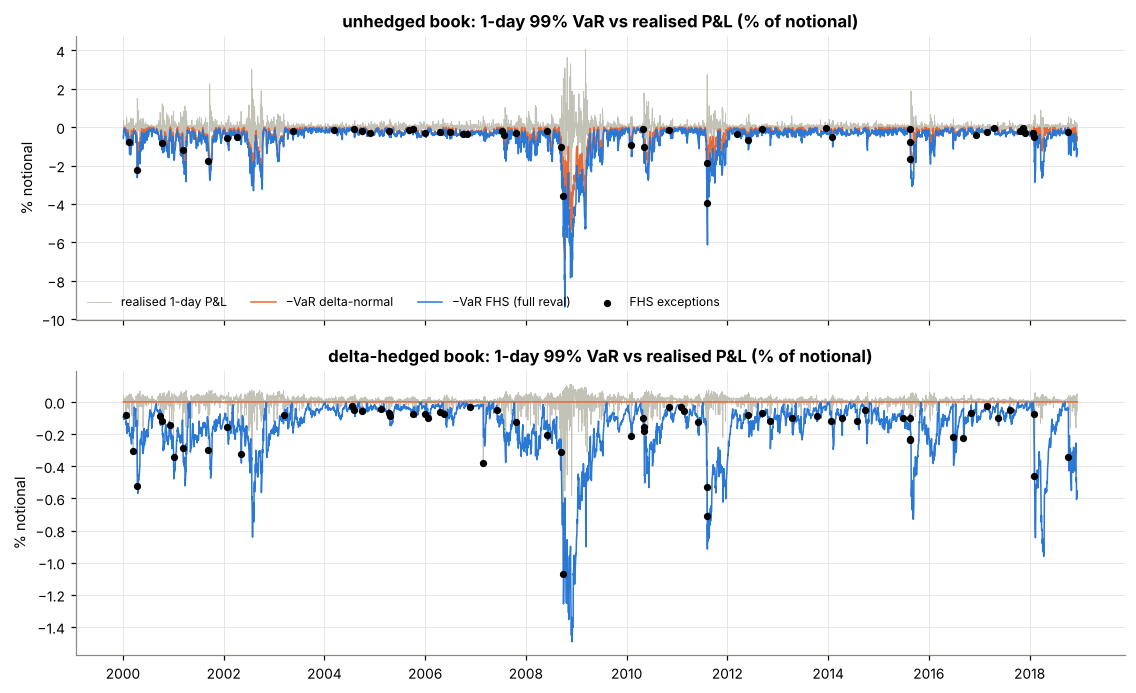

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(10.5, 6.4), sharex=True)
for a, book in zip(ax, ["unhedged", "delta-hedged"]):
    sub = vr[vr.book == book]
    a.plot(sub.date, sub.act, color="#c3c2b7", lw=0.6, label="realised 1-day P&L")
    a.plot(sub.date, -sub.dn, color=PAL[1], lw=1.0, label="−VaR delta-normal"); a.plot(sub.date, -sub.fhs, color=PAL[0], lw=1.0, label="−VaR FHS (full reval)")
    ex = sub.act.values < -sub.fhs.values; a.scatter(sub.date[ex], sub.act[ex], s=14, color="black", zorder=5, label="FHS exceptions")
    a.set_title(f"{book} book: 1-day 99% VaR vs realised P&L (% of notional)"); a.set_ylabel("% notional")
ax[0].legend(ncol=4, fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()